<a href="https://colab.research.google.com/github/bethoven996/tuia-dog-recognition-app/blob/feature%2Ftp2-razas-perros/2-train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

El entrenamiento se realiza en Colab para aprovechar la GPU:
**Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.

Requisitos previos (en tu fork):

- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:

- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.
- Entregar esta notebook ejecutada, con sus salidas.


**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).


## Equipo

- Alumno 1 :Norberto Narvaez
- Alumno 2 :


## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.


In [4]:
import sys

IN_COLAB = "google.colab" in sys.modules

In [5]:
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    REPO_URL = "https://github.com/bethoven996/tuia-dog-recognition-app.git"
    BRANCH = "feature/tp2-razas-perros"  # no main: main tiene que quedar igual al repo base
    !git clone -b $BRANCH $REPO_URL proyecto
    %cd proyecto
else:
    print("Entorno local: el repo ya está clonado, no se clona de nuevo.")

Cloning into 'proyecto'...
remote: Enumerating objects: 168, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 168 (delta 28), reused 21 (delta 21), pack-reused 126 (from 2)
Receiving objects: 100% (168/168), 21.94 MiB | 29.37 MiB/s, done.
Resolving deltas: 100% (85/85), done.
/content/proyecto


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.


In [6]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.


In [7]:
import os
import sys
from pathlib import Path

os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data/dataset
GPU disponible: True


## 4. Dataset y splits

Descargar el dataset y cargar los splits y el conjunto independiente definidos en
`1-pre-processing.ipynb`.


In [10]:
import shutil
import zipfile
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

# Dataset de Kaggle (si ya está descargado, el script no lo vuelve a copiar)
!"{sys.executable}" scripts/download_dataset.py


def extraer_zip(zip_path, destino):
    """Extrae un zip creado en Windows: Compress-Archive puede guardar las rutas con '\\'."""
    with zipfile.ZipFile(zip_path) as z:
        for info in z.infolist():
            nombre = info.filename.replace("\\", "/")
            ruta = destino / nombre
            if nombre.endswith("/"):
                ruta.mkdir(parents=True, exist_ok=True)
            else:
                ruta.parent.mkdir(parents=True, exist_ok=True)
                ruta.write_bytes(z.read(info))


# Conjunto independiente: en local ya está en data/dataset/independent; en Colab se trae de Drive
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    extraer_zip(Path("/content/drive/MyDrive/tp2/independent.zip"), settings.dataset_path)

# Splits definidos en 1-pre-processing.ipynb (rutas relativas a DATASET_PATH)
SPLITS = ["train", "valid", "test", "independent"]
splits = pd.read_csv(settings.data_path / "splits.csv")
splits["abs"] = splits["path"].map(lambda p: settings.dataset_path / p)

faltan = int((~splits["abs"].map(Path.exists)).sum())
print("Imágenes del CSV que no se encuentran en disco:", faltan)
display(splits["split"].value_counts().reindex(SPLITS).rename("imágenes"))

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Using Colab cache for faster access to the '70-dog-breedsimage-data-set' dataset.
Ya existe, se omite: /content/proyecto/data/dataset/valid
Ya existe, se omite: /content/proyecto/data/dataset/dogs.csv
Ya existe, se omite: /content/proyecto/data/dataset/test
Ya existe, se omite: /content/proyecto/data/dataset/train
Dataset disponible en /content/proyecto/data/dataset
Mounted at /content/drive
Imágenes del CSV que no se encuentran en disco: 0


,imágenes
split,
train,7652
valid,685
test,696
independent,184


## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

TO-DO:

- Galería: imágenes de `train`. Consultas: `test` y el conjunto independiente (nunca indexadas).
- Para cada consulta, recuperar las Top-10 y calcular NDCG@10 con relevancia binaria (misma raza).
- Reportar NDCG@10 medio, precision@10 y accuracy de la raza predicha, por separado para `test` y
  para el conjunto independiente.
- Comparar `cosine` vs `l2`, analizar `TOP_K` y calibrar `SIMILARITY_THRESHOLD` con validación.
- Justificar el resultado con ejemplos de consultas y sus Top-10.

Sugerencia: no hace falta la base de datos. Calculá los embeddings de la galería en una matriz de
`numpy` y buscá con un producto matricial (`EmbeddingStore.append` reescribe el JSON en cada llamada).


In [17]:
from lib.bootstrap import build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k
from lib.schemas import Neighbor

similarity = build_similarity(settings, build_store(settings))

CACHE = settings.output_path / "emb_baseline.npz"
paths = [str(p) for p in splits["abs"]]
if CACHE.exists() and list(np.load(CACHE)["paths"]) == paths:
    E_base = np.load(CACHE)["emb"]
    print("Embeddings leídos de", CACHE)
else:
    E_base = np.array([similarity.extract_embedding(cv2.imread(p)) for p in tqdm(paths)], dtype=np.float32)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    np.savez(CACHE, emb=E_base, paths=np.array(paths))

print("Matriz de embeddings:", E_base.shape)

Embeddings leídos de output/emb_baseline.npz
Matriz de embeddings: (9217, 512)


In [18]:
TRAIN = splits["split"].eq("train").to_numpy()
razas_g = splits.loc[TRAIN, "breed"].to_numpy()
n_rel = pd.Series(razas_g).value_counts()  # imágenes de cada raza en la galería (para el NDCG ideal)


def evaluar_busqueda(E, consulta, metrica="cosine", k=10, umbral=0.0):
    """Busca cada consulta en la galería (train) y devuelve una fila de métricas por consulta."""
    G = E[TRAIN]
    q = splits["split"].eq(consulta).to_numpy()
    Q, razas_q = E[q], splits.loc[q, "breed"].to_numpy()

    S = Q @ G.T  # similitud coseno (los vectores están normalizados)
    if metrica == "l2":
        S = 1 / (1 + np.sqrt(np.clip(2 - 2 * S, 0, None)))  # misma fórmula que el servicio: 1 / (1 + distancia)
    top = np.argsort(-S, axis=1)[:, :k]

    similarity.similarity_threshold = umbral
    filas = []
    for i in range(len(Q)):
        rel = (razas_g[top[i]] == razas_q[i]).astype(float)
        vecinos = [Neighbor(path=str(j), breed=razas_g[j], score=float(S[i, j])) for j in top[i]]
        pred, _ = similarity.predict_breed_from_neighbors(vecinos)  # la misma función que usa la app
        filas.append({
            "raza": razas_q[i],
            "ndcg": ndcg_at_k(rel, k=k, n_relevant=int(n_rel[razas_q[i]])),
            "precision": rel.mean(),
            "pred": pred,
            "acierto": pred == razas_q[i],
            "mejor_score": float(S[i, top[i][0]]),
            "top": top[i],
        })
    return pd.DataFrame(filas)


resultados = {}
tabla = []
for metrica in ["cosine", "l2"]:
    for consulta in ["test", "independent"]:
        r = evaluar_busqueda(E_base, consulta, metrica)
        resultados[(metrica, consulta)] = r
        tabla.append({"métrica": metrica, "consultas": consulta, "n": len(r),
                      "NDCG@10": r["ndcg"].mean(), "Precision@10": r["precision"].mean(),
                      "Accuracy raza": r["acierto"].mean()})
display(pd.DataFrame(tabla).round(3))

,métrica,consultas,n,NDCG@10,Precision@10,Accuracy raza
0,cosine,test,696,0.873,0.860,0.932
1,cosine,independent,184,0.474,0.467,0.565
2,l2,test,696,0.873,0.860,0.932
3,l2,independent,184,0.474,0.467,0.565


**Resultados del baseline (ResNet18 preentrenada en ImageNet, sin entrenamiento)**

En test, la búsqueda alcanza NDCG@10 = 0,873, Precision@10 = 0,860 y una accuracy de raza de 0,932 por
voto ponderado, sin entrenar ningún modelo: los embeddings genéricos de ImageNet ya separan bien las razas
del dataset. `cosine` y `l2` dan resultados idénticos en todas las métricas: con embeddings normalizados L2
ambas métricas ordenan los vecinos de la misma forma (distancia² = 2 − 2·coseno), y solo cambia la escala
del score.

En el conjunto independiente el rendimiento cae a NDCG@10 = 0,474 y accuracy = 0,565. La caída refleja el
cambio de dominio: en el dataset el perro ocupa el 80–100 % de la imagen (6.4 de la notebook 1), mientras
que las fotos de Wikimedia tienen el perro más chico, más fondo y proporciones no cuadradas. Además, el
conjunto independiente se construyó con razas fáciles de confundir, por lo que es más difícil que el
promedio de test.


Accuracy        NDCG@k       
consultas     test  valid   test  valid
TOP_K                                  
1            0.925  0.902  0.925  0.902
3            0.934  0.924  0.904  0.893
5            0.940  0.928  0.893  0.882
10           0.932  0.937  0.873  0.864
20           0.930  0.923  0.844  0.839

Umbral elegido (p2 de valid): 0.836
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 123MB/s]


Perros de valid rechazados como 'unknown': 2.0%
Imágenes sin perros rechazadas como 'unknown': 95.2% (21 imágenes)


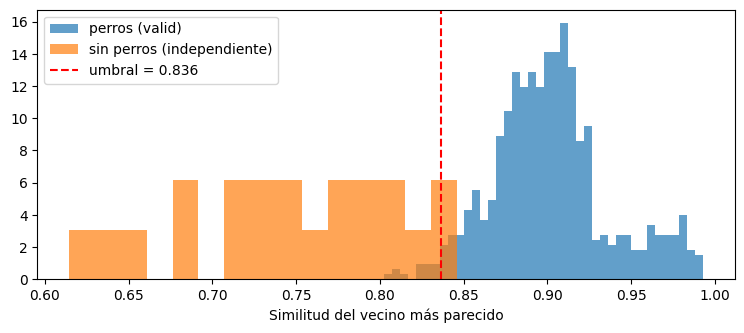

In [19]:
# 1) Efecto de TOP_K: se elige con valid, se reporta también test
filas = []
for k in [1, 3, 5, 10, 20]:
    for consulta in ["valid", "test"]:
        r = evaluar_busqueda(E_base, consulta, "cosine", k=k)
        filas.append({"TOP_K": k, "consultas": consulta, "Accuracy": r["acierto"].mean(), "NDCG@k": r["ndcg"].mean()})
display(pd.DataFrame(filas).pivot(index="TOP_K", columns="consultas", values=["Accuracy", "NDCG@k"]).round(3))

# 2) Umbral: percentil 2 del mejor score de los perros de valid (regla fijada antes de mirar resultados)
r_valid = evaluar_busqueda(E_base, "valid", "cosine")
UMBRAL = float(np.quantile(r_valid["mejor_score"], 0.02))
print(f"Umbral elegido (p2 de valid): {UMBRAL:.3f}")

# Solo para reportar: ¿cuántas imágenes sin perros quedan por debajo del umbral?
IND = settings.dataset_path / "independent"
fuentes = pd.read_csv(IND / "fuentes.csv")
sin_perros = fuentes[fuentes["tipo"] == "sin_perro"]
E_sin = np.array([similarity.extract_embedding(cv2.imread(str(IND / a))) for a in sin_perros["archivo"]], dtype=np.float32)
mejor_sin = (E_sin @ E_base[TRAIN].T).max(axis=1)
print(f"Perros de valid rechazados como 'unknown': {(r_valid['mejor_score'] < UMBRAL).mean():.1%}")
print(f"Imágenes sin perros rechazadas como 'unknown': {(mejor_sin < UMBRAL).mean():.1%} ({len(mejor_sin)} imágenes)")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(r_valid["mejor_score"], bins=40, alpha=0.7, label="perros (valid)", density=True)
ax.hist(mejor_sin, bins=15, alpha=0.7, label="sin perros (independiente)", density=True)
ax.axvline(UMBRAL, color="red", ls="--", label=f"umbral = {UMBRAL:.3f}")
ax.set_xlabel("Similitud del vecino más parecido")
ax.legend()
plt.show()

**`TOP_K` y umbral de similitud**

- **TOP_K = 10**, elegido con valid (accuracy 0,937, la más alta en ese split). Con pocos vecinos la
  predicción depende demasiado del primero (k = 1: 0,902 en valid) y con muchos entran vecinos de otras
  razas a la votación (k = 20: 0,923). En test, k = 5 da un valor apenas mayor (0,940 contra 0,932), pero
  la elección se hace con valid para no ajustar con el conjunto de evaluación. El NDCG@k disminuye al
  aumentar k porque es más difícil que todas las posiciones de un ranking largo sean de la raza correcta.
- **SIMILARITY_THRESHOLD = 0,836** (métrica coseno). Valid solo contiene perros de las 70 razas, por lo
  que optimizar el umbral únicamente con ese split llevaría siempre al valor más bajo. Se fijó de antemano
  una regla: el umbral es el percentil 2 de la similitud del vecino más parecido en valid, es decir, se
  acepta rechazar como `unknown` al 2 % de los perros reales. Con ese umbral se rechaza el 95,2 % de las
  imágenes sin perros del conjunto independiente (20 de 21), que se usaron solo para reportar, no para
  elegir. Las distribuciones de ambos grupos se superponen apenas entre 0,80 y 0,85. El umbral corresponde
  a la métrica coseno: con L2 el score tiene otra escala y habría que recalibrarlo.


Las 10 razas con peor NDCG@10 en test:


,NDCG test,Acc test,NDCG indep,Acc indep
raza,,,,
Bulldog,0.33,0.30,NaN,NaN
Malinois,0.55,0.80,0.64,0.88
Labradoodle,0.63,0.70,0.20,0.22
Cockapoo,0.63,0.78,0.19,0.10
Boston Terrier,0.65,0.80,0.42,0.50
Rhodesian,0.66,0.70,0.67,1.00
Bull Mastiff,0.67,0.70,NaN,NaN
Bull Terrier,0.68,0.70,NaN,NaN
American Hairless,0.69,0.70,NaN,NaN



Confusiones más frecuentes en test (real -> predicha):


,,veces
raza,pred,
Bulldog,Boston Terrier,4
Bull Mastiff,Boxer,3
American Hairless,Mex Hairless,3
Labradoodle,Cockapoo,3
Boston Terrier,Bulldog,2
Bull Terrier,Basenji,2
American Spaniel,Irish Spaniel,2
German Sheperd,Malinois,2
Cockapoo,Labradoodle,2


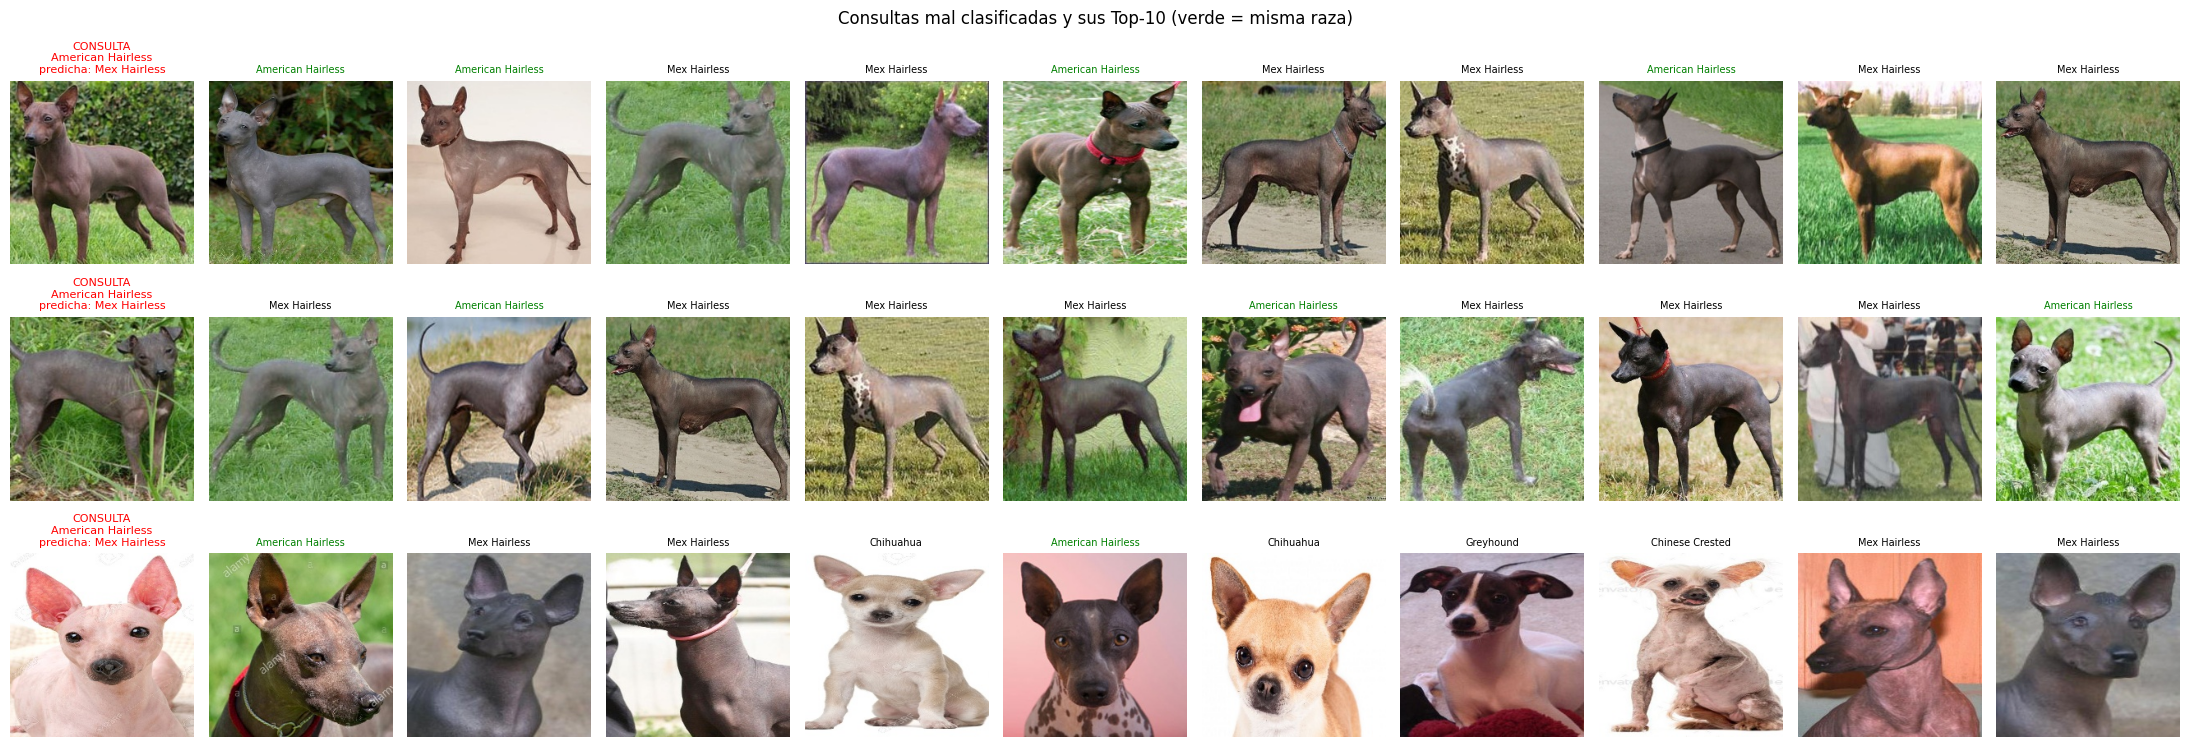

In [20]:
r_test = resultados[("cosine", "test")]
r_ind = resultados[("cosine", "independent")]

# 1) Razas con peor NDCG@10 en test y en el conjunto independiente
por_raza = pd.DataFrame({
    "NDCG test": r_test.groupby("raza")["ndcg"].mean(),
    "Acc test": r_test.groupby("raza")["acierto"].mean(),
    "NDCG indep": r_ind.groupby("raza")["ndcg"].mean(),
    "Acc indep": r_ind.groupby("raza")["acierto"].mean(),
})
print("Las 10 razas con peor NDCG@10 en test:")
display(por_raza.sort_values("NDCG test").head(10).round(2))

# 2) Con qué raza se confunden los errores
errores = r_test[~r_test["acierto"]]
print("\nConfusiones más frecuentes en test (real -> predicha):")
display(errores.groupby(["raza", "pred"]).size().sort_values(ascending=False).head(10).rename("veces"))

# 3) Ejemplos visuales: consultas mal clasificadas y sus Top-10
paths_g = splits.loc[TRAIN, "abs"].to_numpy()
paths_test = splits.loc[splits["split"].eq("test"), "abs"].to_numpy()
ejemplos = errores.head(3)
fig, axes = plt.subplots(len(ejemplos), 11, figsize=(22, 2.6 * len(ejemplos)), squeeze=False)
for fila_ax, (i, fila) in zip(axes, ejemplos.iterrows()):
    fila_ax[0].imshow(cv2.imread(str(paths_test[i]))[:, :, ::-1])
    fila_ax[0].set_title(f"CONSULTA\n{fila['raza']}\npredicha: {fila['pred']}", fontsize=8, color="red")
    for ax, j in zip(fila_ax[1:], fila["top"]):
        ax.imshow(cv2.imread(str(paths_g[j]))[:, :, ::-1])
        ax.set_title(razas_g[j], fontsize=7, color="green" if razas_g[j] == fila["raza"] else "black")
    for ax in fila_ax:
        ax.axis("off")
plt.suptitle("Consultas mal clasificadas y sus Top-10 (verde = misma raza)")
plt.tight_layout()
plt.show()

**Análisis de errores**

Las confusiones más frecuentes en test coinciden con los pares de razas parecidas identificados en el EDA
(sección 6.3 de la notebook 1): Labradoodle ↔ Cockapoo, American Hairless → Mex Hairless, German Sheperd →
Malinois, Rhodesian → Vizsla y Bulldog ↔ Boston Terrier. American Spaniel → Irish Spaniel es además uno de
los pares con etiquetas en conflicto detectados por la regla 6, lo que indica que la confusión afecta
también al etiquetado del dataset.

La raza con peor resultado es Bulldog (NDCG@10 = 0,33, accuracy = 0,30), confundida con Boston Terrier.
En la inspección visual del EDA ya se había encontrado una imagen etiquetada como "Bulldog" que parece un
Boston Terrier: si hay varias en la galería, las búsquedas de ambas razas se mezclan. Es una hipótesis de
ruido en las etiquetas.

En el conjunto independiente fallan sobre todo las cruzas (Labradoodle: accuracy 0,22; Cockapoo: 0,10),
que no tienen un estándar de raza fijo y varían mucho entre ejemplares, mientras que razas con rasgos
distintivos como Rhodesian (1,00) o Malinois (0,88) se reconocen bien con fotos nuevas.

Los ejemplos visuales muestran el mecanismo del error: American Hairless y Mex Hairless son prácticamente
indistinguibles y las vecinas se reparten entre ambas razas; en el primer caso las dos vecinas más
parecidas son de la raza correcta, pero el voto lo gana la otra raza por tener más vecinas en el Top-10.
En el tercero, un primer plano, la forma de las orejas atrae vecinas de Chihuahua.


## 6. Modelo A (obligatorio): fine-tuning de ResNet

`train_classifier` debe guardar el checkpoint en `models/resnet18_finetuned.pth`
(o el nombre configurado en `RESNET18_MODEL_NAME`). Documentar la estrategia de fine-tuning
y los hiperparámetros utilizados (learning rate, batch size, epochs, optimizador, scheduler,
regularización).


In [20]:
!git pull
import importlib
import lib.services.classifier_service
import lib.bootstrap
importlib.reload(lib.services.classifier_service)
importlib.reload(lib.bootstrap)
print("Código actualizado")

remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 9 (delta 4), reused 9 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (9/9), 6.89 KiB | 441.00 KiB/s, done.
From https://github.com/bethoven996/tuia-dog-recognition-app
   d72d4a3..a56486f  feature/tp2-razas-perros -> origin/feature/tp2-razas-perros
Updating d72d4a3..a56486f
Fast-forward
 src/lib/models/__init__.py             |   0
 src/lib/models/cnn_custom.py           |  44 ++++++++
 src/lib/services/classifier_service.py | 184 ++++++++++++++++++++++++++++++++-
 src/lib/training.py                    |  69 +++++++++++++
 4 files changed, 293 insertions(+), 4 deletions(-)
 create mode 100644 src/lib/models/__init__.py
 create mode 100644 src/lib/models/cnn_custom.py
 create mode 100644 src/lib/training.py
Código actualizado


In [21]:
import json
from lib.bootstrap import build_classifier

classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
HIST_A = settings.output_path / "history_resnet18_finetuned.json"
historiales_a = {}

# Estrategia 1: feature extraction (backbone congelado, solo se entrena la capa nueva)
classifier.hparams = {"strategy": "feature_extraction", "epochs": 8}
classifier.train_classifier()
historiales_a["feature_extraction"] = json.loads(HIST_A.read_text())
valid_fe = classifier.evaluate_classifier(split="valid")

# Estrategia 2: fine-tuning completo con learning rates diferenciados (queda como checkpoint final)
classifier.hparams = {"strategy": "fine_tuning"}
classifier.train_classifier()
historiales_a["fine_tuning"] = json.loads(HIST_A.read_text())
valid_ft = classifier.evaluate_classifier(split="valid")

print("Hiperparámetros del modelo final:")
display(pd.Series(historiales_a["fine_tuning"]["hparams"]))
print("Comparación de estrategias en valid:")
display(pd.DataFrame({"feature extraction": valid_fe, "fine-tuning": valid_ft}).round(3))

Hiperparámetros del modelo final:


,0
strategy,fine_tuning
epochs,10
batch_size,64
lr_head,0.001
lr_backbone,0.0001
weight_decay,0.0001
label_smoothing,0.1
patience,3
class_weights,False
seed,42


Comparación de estrategias en valid:


,feature extraction,fine-tuning
accuracy,0.931,0.969
precision,0.938,0.972
recall,0.932,0.969
specificity,0.999,1.000
f1,0.932,0.969


In [22]:
metrics_a = classifier.evaluate_classifier()  # test
pred_a = classifier.last_predictions.copy()
pd.Series(metrics_a).round(3)

,0
accuracy,0.966
precision,0.967
recall,0.966
specificity,1.000
f1,0.965


### Curvas de entrenamiento y matriz de confusión (Modelo A)

TO-DO: graficar las curvas de entrenamiento/validación (loss y accuracy) y la matriz de confusión
normalizada, con los pares de razas más confundidos.


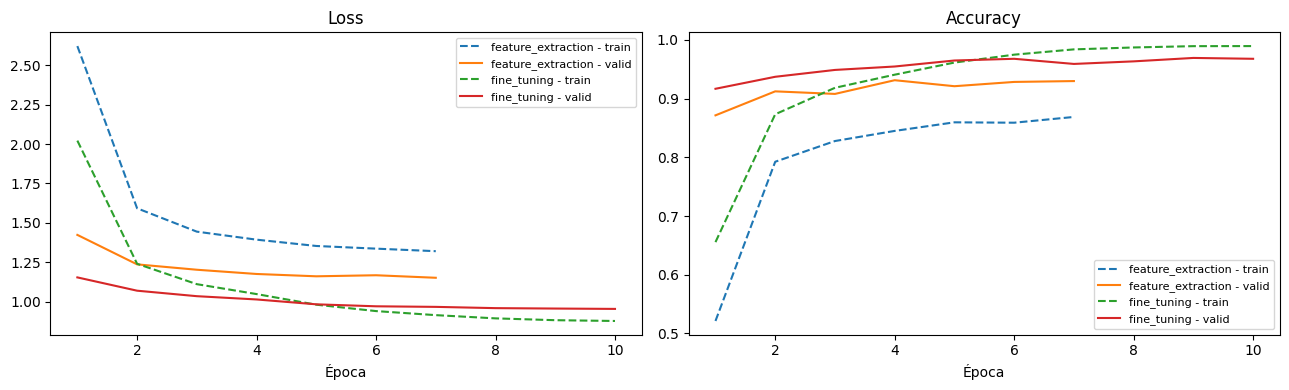

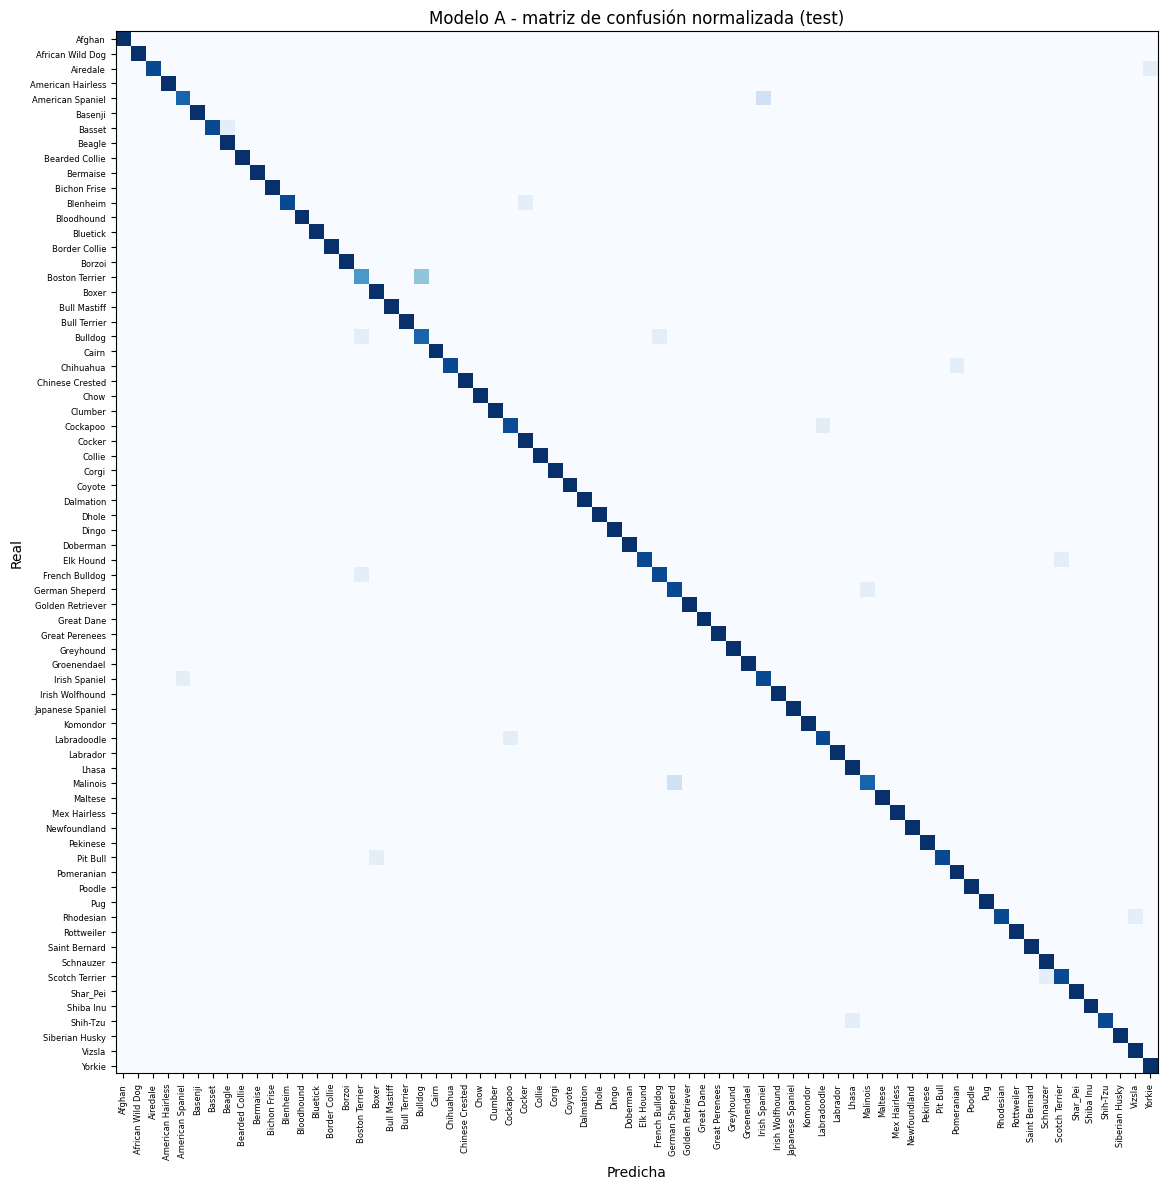

Pares más confundidos (real -> predicha):


,,veces
breed,pred,
Boston Terrier,Bulldog,4
Malinois,German Sheperd,2
American Spaniel,Irish Spaniel,2
Basset,Beagle,1
Airedale,Yorkie,1
Bulldog,Boston Terrier,1
Blenheim,Cocker,1
Chihuahua,Pomeranian,1
Cockapoo,Labradoodle,1


Razas con peor accuracy en test:


,acierto
breed,
Boston Terrier,0.60
American Spaniel,0.80
Bulldog,0.80
Malinois,0.80
Cockapoo,0.89
Chihuahua,0.90
Basset,0.90
Airedale,0.90
Irish Spaniel,0.90


In [23]:
# Curvas de entrenamiento de las dos estrategias
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for estrategia, h in historiales_a.items():
    hist = pd.DataFrame(h["historial"])
    axes[0].plot(hist["epoca"], hist["train_loss"], "--", label=f"{estrategia} - train")
    axes[0].plot(hist["epoca"], hist["val_loss"], label=f"{estrategia} - valid")
    axes[1].plot(hist["epoca"], hist["train_acc"], "--", label=f"{estrategia} - train")
    axes[1].plot(hist["epoca"], hist["val_acc"], label=f"{estrategia} - valid")
axes[0].set_title("Loss")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Matriz de confusión normalizada (cada fila suma 1)
clases = list(classifier.load_model().classes)
cm = pd.crosstab(pred_a["breed"], pred_a["pred"], normalize="index").reindex(index=clases, columns=clases, fill_value=0)
fig, ax = plt.subplots(figsize=(14, 12))
ax.imshow(cm.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(clases)))
ax.set_xticklabels(clases, rotation=90, fontsize=6)
ax.set_yticks(range(len(clases)))
ax.set_yticklabels(clases, fontsize=6)
ax.set_xlabel("Predicha")
ax.set_ylabel("Real")
ax.set_title("Modelo A - matriz de confusión normalizada (test)")
plt.tight_layout()
plt.show()

print("Pares más confundidos (real -> predicha):")
display(pred_a[~pred_a["acierto"]].groupby(["breed", "pred"]).size().sort_values(ascending=False).head(10).rename("veces"))
print("Razas con peor accuracy en test:")
display(pred_a.groupby("breed")["acierto"].mean().sort_values().head(10).round(2))

In [24]:
# Copia los checkpoints y los historiales a Google Drive (solo en Colab)
if IN_COLAB:
    destino = Path("/content/drive/MyDrive/tp2")
    shutil.copytree(settings.model_path, destino / "models", dirs_exist_ok=True)
    shutil.copytree(settings.output_path, destino / "output", dirs_exist_ok=True)
    print("Guardado en Drive:", sorted(p.name for p in (destino / "models").iterdir()))

Guardado en Drive: ['.gitkeep', 'resnet18_finetuned.pth']


**Análisis del Modelo A (ResNet18 con fine-tuning)**

**Estrategias comparadas (en valid).** Con feature extraction (backbone congelado, solo se entrena la capa
final) se alcanza una accuracy de 0,931, prácticamente igual a la búsqueda por similitud del baseline: se
aprovechan los mismos embeddings de ImageNet sin adaptarlos. El fine-tuning completo, con learning rates
diferenciados (0,001 para la capa nueva y 0,0001 para el backbone preentrenado), llega a 0,969: ajustar
toda la red le permite aprender rasgos propios de las razas. Se elige fine-tuning como modelo final.

**Hiperparámetros:** AdamW, batch de 64, hasta 10 épocas con scheduler coseno, weight decay 1e-4, label
smoothing 0,1, early stopping con paciencia 3 sobre la accuracy de valid (se guarda el mejor checkpoint,
no el de la última época), data augmentation de la sección 10 de la notebook 1 y semilla 42.

**Resultados en test:** accuracy 0,966, precision 0,967, recall 0,966, F1 0,965 (macro). Frente a la
búsqueda por similitud del baseline (accuracy 0,932) los errores se reducen a la mitad. Valid (0,969) y
test (0,966) dan prácticamente igual, por lo que el modelo no quedó sobreajustado a valid al elegir el
checkpoint. Precision, recall y F1 son muy parecidos porque test está casi balanceado. La specificity
macro es 1,000: con 70 clases cada raza tiene muchísimos verdaderos negativos, por lo que esta métrica es
poco informativa en este problema.

**Curvas:** en fine-tuning la accuracy de valid se estabiliza en ~0,97 desde la época 6, mientras la loss
de train sigue bajando y la de valid queda plana: hay un leve sobreajuste al final (train ~0,99 vs valid
~0,97), sin efecto sobre el modelo final porque se guarda el mejor checkpoint según valid. Feature
extraction se detiene por early stopping en la época 7. La accuracy de train queda por debajo de la de
valid en feature extraction porque train se mide con data augmentation, y las losses no bajan de ~0,74
por el label smoothing.

**Errores:** las confusiones son los mismos pares que en la Etapa 1 y en el EDA: Boston Terrier → Bulldog
(4 casos; Boston Terrier es la raza con peor accuracy, 0,60), Malinois → German Sheperd, American Spaniel →
Irish Spaniel (par con etiquetas en conflicto en la regla 6) y Cockapoo → Labradoodle. La confusión
Boston Terrier / Bulldog refuerza la hipótesis de ruido en las etiquetas de esas razas. El fine-tuning sí
resolvió el par American Hairless / Mex Hairless, que era de los peores en la búsqueda por similitud.

## 7. Modelo B (obligatorio): CNN propia

`train_classifier` con el modelo activo `cnn_custom` debe guardar el checkpoint en
`models/cnn_custom.pth` (o el nombre configurado en `CNN_CUSTOM_MODEL_NAME`).
Definí la arquitectura en un módulo importable (por ejemplo, `src/lib/models/cnn_custom.py`):
si la clase vive en la notebook, `torch.load` falla en la app.

TO-DO: documentar la arquitectura (capas, parámetros, dimensión del embedding), los
hiperparámetros y la tabla de experimentos.


In [25]:
from lib.models.cnn_custom import CNNCustom

cnn = CNNCustom(num_classes=70)
print(cnn)
n_cnn = sum(p.numel() for p in cnn.parameters())
n_resnet = sum(p.numel() for p in classifier.load_model("resnet18_finetuned").parameters())
print(f"\nParámetros CNN propia: {n_cnn / 1e6:.2f} M")
print(f"Parámetros ResNet18 (Modelo A): {n_resnet / 1e6:.2f} M")

CNNCustom(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, tr

In [26]:
classifier.set_active_model("cnn_custom")
HIST_B = settings.output_path / "history_cnn_custom.json"
CKPT_B = classifier.active_checkpoint

experimentos_b = {
    "base": {},                               # hiperparámetros por defecto (training.py)
    "class_weights": {"class_weights": True}, # más peso en la pérdida a las razas con menos imágenes
}
historiales_b, valid_b = {}, {}
for nombre, extra in experimentos_b.items():
    classifier.hparams = extra
    classifier.train_classifier()
    historiales_b[nombre] = json.loads(HIST_B.read_text())
    valid_b[nombre] = classifier.evaluate_classifier(split="valid")
    shutil.copy(CKPT_B, CKPT_B.with_name(f"cnn_custom_{nombre}.pth"))  # se guarda cada experimento

# Se queda como checkpoint final el experimento con mejor accuracy en valid
mejor_b = max(valid_b, key=lambda k: valid_b[k]["accuracy"])
shutil.copy(CKPT_B.with_name(f"cnn_custom_{mejor_b}.pth"), CKPT_B)
classifier._loaded.pop("cnn_custom", None)

tabla_b = pd.DataFrame({
    n: {"épocas entrenadas": len(historiales_b[n]["historial"]), **valid_b[n]} for n in experimentos_b
}).T
print("Tabla de experimentos (valid):")
display(tabla_b.round(3))
print("Experimento elegido:", mejor_b)
print("Hiperparámetros:")
display(pd.Series(historiales_b[mejor_b]["hparams"]))

Tabla de experimentos (valid):


,épocas entrenadas,accuracy,precision,recall,specificity,f1
base,40.0,0.866,0.873,0.865,0.998,0.862
class_weights,40.0,0.861,0.872,0.861,0.998,0.857


Experimento elegido: base
Hiperparámetros:


,0
epochs,40
batch_size,64
lr,0.001
weight_decay,0.0001
label_smoothing,0.1
dropout,0.3
embedding_dim,512
patience,6
class_weights,False
seed,42


In [27]:
metrics_b = classifier.evaluate_classifier()  # test, con el experimento elegido
pred_b = classifier.last_predictions.copy()
pd.Series(metrics_b).round(3)

,0
accuracy,0.818
precision,0.835
recall,0.817
specificity,0.997
f1,0.816


### Curvas de entrenamiento y matriz de confusión (Modelo B)


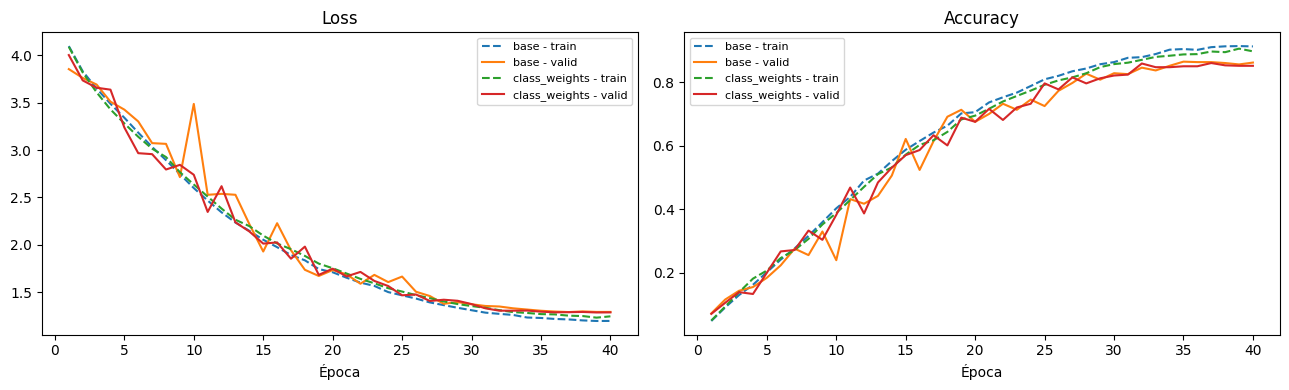

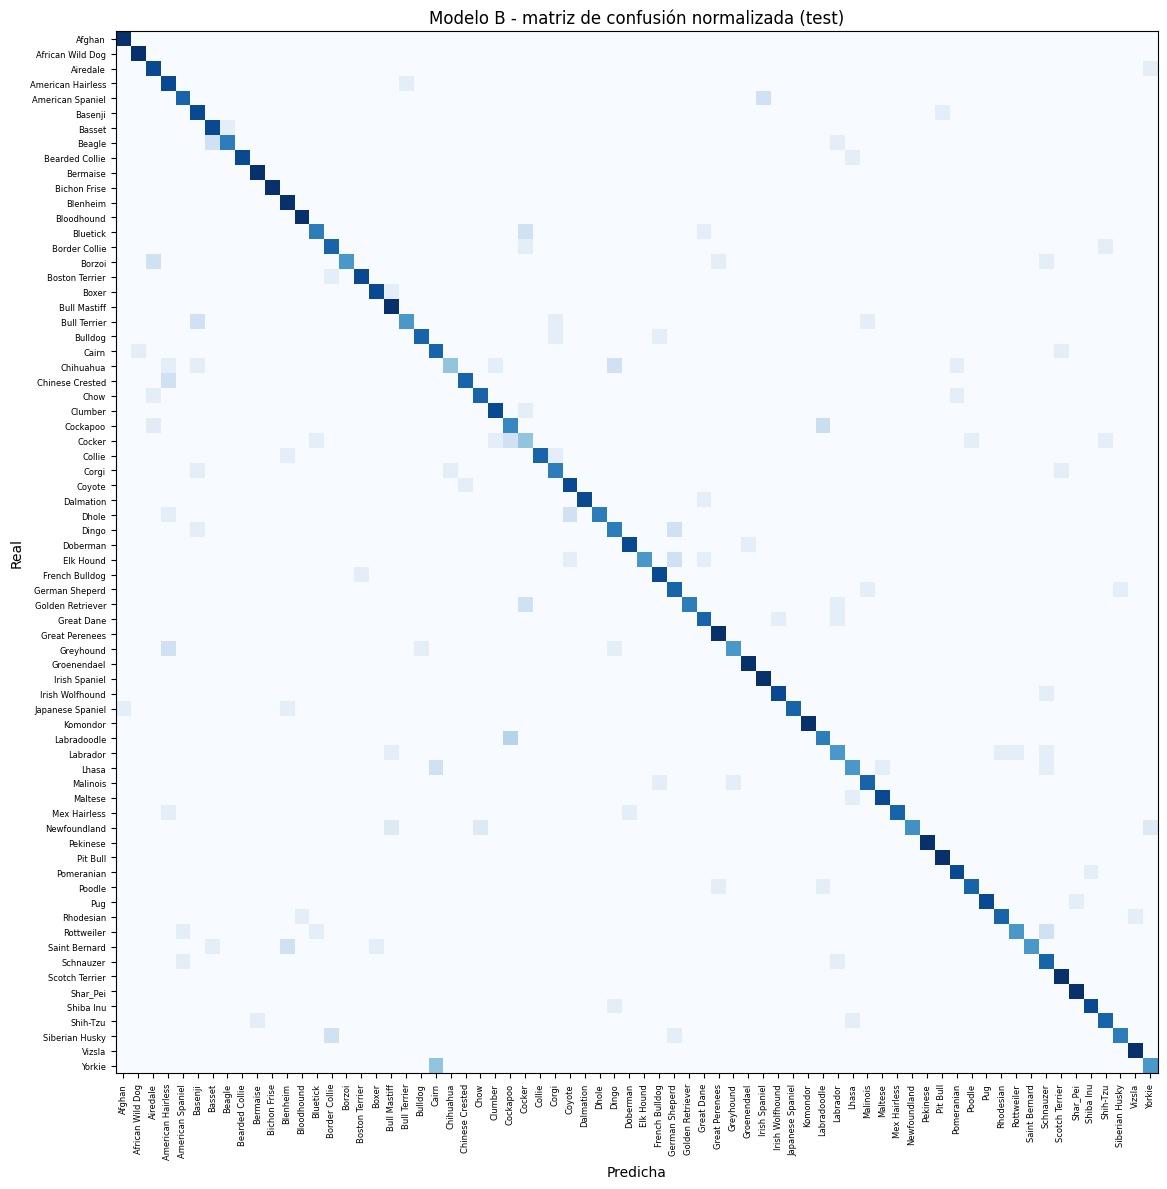

Pares más confundidos (real -> predicha):


,,veces
breed,pred,
Yorkie,Cairn,4
Labradoodle,Cockapoo,3
American Spaniel,Irish Spaniel,2
Beagle,Basset,2
Chihuahua,Dingo,2
Bull Terrier,Basenji,2
Cocker,Cockapoo,2
Cockapoo,Labradoodle,2
Chinese Crested,American Hairless,2


Razas con peor accuracy en test:


,acierto
breed,
Cocker,0.4
Chihuahua,0.4
Borzoi,0.6
Bull Terrier,0.6
Labrador,0.6
Lhasa,0.6
Greyhound,0.6
Elk Hound,0.6
Rottweiler,0.6


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for nombre, h in historiales_b.items():
    hist = pd.DataFrame(h["historial"])
    axes[0].plot(hist["epoca"], hist["train_loss"], "--", label=f"{nombre} - train")
    axes[0].plot(hist["epoca"], hist["val_loss"], label=f"{nombre} - valid")
    axes[1].plot(hist["epoca"], hist["train_acc"], "--", label=f"{nombre} - train")
    axes[1].plot(hist["epoca"], hist["val_acc"], label=f"{nombre} - valid")
axes[0].set_title("Loss")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

clases = list(classifier.load_model().classes)
cm = pd.crosstab(pred_b["breed"], pred_b["pred"], normalize="index").reindex(index=clases, columns=clases, fill_value=0)
fig, ax = plt.subplots(figsize=(14, 12))
ax.imshow(cm.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(clases)))
ax.set_xticklabels(clases, rotation=90, fontsize=6)
ax.set_yticks(range(len(clases)))
ax.set_yticklabels(clases, fontsize=6)
ax.set_xlabel("Predicha")
ax.set_ylabel("Real")
ax.set_title("Modelo B - matriz de confusión normalizada (test)")
plt.tight_layout()
plt.show()

print("Pares más confundidos (real -> predicha):")
display(pred_b[~pred_b["acierto"]].groupby(["breed", "pred"]).size().sort_values(ascending=False).head(10).rename("veces"))
print("Razas con peor accuracy en test:")
display(pred_b.groupby("breed")["acierto"].mean().sort_values().head(10).round(2))

In [29]:
if IN_COLAB:
    destino = Path("/content/drive/MyDrive/tp2")
    shutil.copytree(settings.model_path, destino / "models", dirs_exist_ok=True)
    shutil.copytree(settings.output_path, destino / "output", dirs_exist_ok=True)
    print("Guardado en Drive:", sorted(p.name for p in (destino / "models").iterdir()))

Guardado en Drive: ['.gitkeep', 'cnn_custom.pth', 'cnn_custom_base.pth', 'cnn_custom_class_weights.pth', 'resnet18_finetuned.pth']


### Análisis del Modelo B (CNN desde cero)

**Arquitectura.** La red tiene 5 bloques convolucionales (dos convoluciones 3×3 con BatchNorm y ReLU, y un MaxPool por bloque), con 32, 64, 128, 256 y 256 filtros. Después hay un Global Average Pooling, una capa de embedding de 512 dimensiones y dropout de 0,3 antes del clasificador de 70 salidas. Tiene unos 2,5 millones de parámetros, contra los ~11 millones de la ResNet18. El Global Average Pooling reemplaza a las capas densas grandes y reduce mucho la cantidad de parámetros, algo importante para entrenar desde cero con ~110 imágenes por raza.

**Experimentos.** Comparé dos variantes en el conjunto de validación: la base y una con pesos por clase en la función de pérdida, para compensar el desbalance.

| Experimento | Accuracy (valid) | F1 macro (valid) |
|---|---|---|
| base | 0,866 | 0,862 |
| class_weights | 0,861 | 0,857 |

La diferencia es de 3 o 4 imágenes sobre 700, dentro del ruido. El dataset está apenas desbalanceado, así que los pesos por clase no tenían mucho que corregir. Me quedé con la variante base por ser la más simple.

**Resultados en test.** Accuracy 0,818, precision macro 0,835, recall macro 0,817 y F1 macro 0,816. La specificity (0,997) casi no informa con 70 clases, por la gran cantidad de verdaderos negativos de cada raza.

Test da unos 5 puntos menos que valid. Parte es ruido: con 700 imágenes, cada accuracy tiene un margen de aproximadamente ±2,7 puntos. La otra parte es el sesgo de selección: elegí el checkpoint y el experimento mirando valid, lo que infla un poco el resultado en ese conjunto. Por eso el resultado que reporto es el de test.

**Curvas.** Train y valid avanzan juntas durante casi todo el entrenamiento y recién se separan levemente al final (train ~0,91, valid ~0,86). No hay un sobreajuste importante: el modelo está limitado por la cantidad de datos y por su capacidad, no por memorizar. Las oscilaciones de valid al principio se deben al learning rate alto y se suavizan cuando el scheduler coseno lo reduce. Los dos experimentos entrenaron las 40 épocas sin que actuara el early stopping, así que con más épocas probablemente se habría ganado algo más de rendimiento.

**Errores.** Las razas con peor resultado en test, como Rottweiler y Saint Bernard (0,60), muestran que la red todavía confunde razas con colores y contexturas parecidas: aprendió sobre todo color y textura, pero no los detalles finos que distinguen razas similares.

**Comparación.** El Modelo B (0,818 en test) queda por debajo del baseline de similitud (0,932 en valid) y del Modelo A (0,966 en test). Era lo esperable: la CNN aprende todo desde cero con ~7.900 imágenes, mientras que la ResNet parte de lo que aprendió con 1,2 millones de imágenes de ImageNet. La diferencia muestra el valor del transfer learning cuando hay pocos datos.

## 8. Evaluación sobre el conjunto independiente

TO-DO: las mismas métricas sobre el conjunto independiente para ambos modelos. Comparar con `test`
y discutir el cambio de dominio.


In [11]:
# Si Colab reinició el entorno, los modelos ya entrenados se recuperan de Drive (no se reentrena nada)
from lib.bootstrap import build_classifier

if IN_COLAB:
    respaldo = Path("/content/drive/MyDrive/tp2")
    shutil.copytree(respaldo / "models", settings.model_path, dirs_exist_ok=True)
    shutil.copytree(respaldo / "output", settings.output_path, dirs_exist_ok=True)

print("Modelos disponibles:", sorted(p.name for p in settings.model_path.glob("*.pth")))
classifier = build_classifier(settings)

Modelos disponibles: ['cnn_custom.pth', 'cnn_custom_base.pth', 'cnn_custom_class_weights.pth', 'resnet18_finetuned.pth']


In [12]:
from lib.evaluation.metrics import precision_recall_f1, specificity


def metricas_macro(pred):
    """Métricas macro promediadas solo sobre las razas presentes en el conjunto evaluado."""
    prec, rec, f1s, espec = [], [], [], []
    for raza in sorted(pred["breed"].unique()):
        tp = int(((pred["pred"] == raza) & (pred["breed"] == raza)).sum())
        fp = int(((pred["pred"] == raza) & (pred["breed"] != raza)).sum())
        fn = int(((pred["pred"] != raza) & (pred["breed"] == raza)).sum())
        tn = len(pred) - tp - fp - fn
        p, r, f = precision_recall_f1(tp, fp, fn)
        prec.append(p)
        rec.append(r)
        f1s.append(f)
        espec.append(specificity(tn, fp))
    return {
        "imágenes": len(pred),
        "razas": pred["breed"].nunique(),
        "accuracy": float(pred["acierto"].mean()),
        "precision": float(np.mean(prec)),
        "recall": float(np.mean(rec)),
        "specificity": float(np.mean(espec)),
        "f1": float(np.mean(f1s)),
    }


preds = {}
for nombre in ["resnet18_finetuned", "cnn_custom"]:
    classifier.set_active_model(nombre)
    for split in ["test", "independent"]:
        classifier.evaluate_classifier(split=split)
        preds[(nombre, split)] = classifier.last_predictions.copy()
classifier.set_active_model("resnet18_finetuned")

razas_ind = set(preds[("resnet18_finetuned", "independent")]["breed"])
filas = {}
for nombre in ["resnet18_finetuned", "cnn_custom"]:
    p_test = preds[(nombre, "test")]
    filas[(nombre, "test (70 razas)")] = metricas_macro(p_test)
    filas[(nombre, "test (mismas razas)")] = metricas_macro(p_test[p_test["breed"].isin(razas_ind)])
    filas[(nombre, "independiente")] = metricas_macro(preds[(nombre, "independent")])

tabla_ind = pd.DataFrame(filas).T
tabla_ind[["accuracy", "precision", "recall", "specificity", "f1"]] = (
    tabla_ind[["accuracy", "precision", "recall", "specificity", "f1"]].astype(float).round(3)
)
tabla_ind

imágenes  razas  accuracy  precision  \
resnet18_finetuned test (70 razas)         696.0   70.0     0.966      0.967   
                   test (mismas razas)     219.0   22.0     0.941      0.962   
                   independiente           184.0   22.0     0.592      0.879   
cnn_custom         test (70 razas)         696.0   70.0     0.818      0.835   
                   test (mismas razas)     219.0   22.0     0.790      0.896   
                   independiente           184.0   22.0     0.321      0.674   

                                        recall  specificity     f1  
resnet18_finetuned test (70 razas)       0.966        1.000  0.965  
                   test (mismas razas)   0.940        0.998  0.949  
                   independiente         0.616        0.993  0.680  
cnn_custom         test (70 razas)       0.817        0.997  0.816  
                   test (mismas razas)   0.789        0.995  0.832  
                   independiente         0.339        0.990  0.403

In [13]:
por_raza = pd.DataFrame({
    "resnet18": preds[("resnet18_finetuned", "independent")].groupby("breed")["acierto"].mean(),
    "cnn_custom": preds[("cnn_custom", "independent")].groupby("breed")["acierto"].mean(),
    "imágenes": preds[("resnet18_finetuned", "independent")]["breed"].value_counts(),
}).sort_values("resnet18").round(2)
print("Accuracy por raza en el conjunto independiente:")
display(por_raza)

for nombre in ["resnet18_finetuned", "cnn_custom"]:
    p = preds[(nombre, "independent")]
    errores = p[~p["acierto"]].groupby(["breed", "pred"]).size().sort_values(ascending=False).head(8)
    print(f"\nConfusiones más frecuentes ({nombre}):")
    display(errores.rename("cantidad").to_frame())

Accuracy por raza en el conjunto independiente:


,resnet18,cnn_custom,imágenes
breed,,,
Siberian Husky,0.20,0.00,10
Labradoodle,0.22,0.22,9
Vizsla,0.22,0.00,9
Beagle,0.40,0.10,10
Cockapoo,0.40,0.10,10
Chihuahua,0.44,0.33,9
German Sheperd,0.50,0.50,10
Golden Retriever,0.50,0.20,10
Bichon Frise,0.57,0.43,7



Confusiones más frecuentes (resnet18_finetuned):


,,cantidad
breed,pred,
Vizsla,Rhodesian,5
Labradoodle,American Spaniel,4
Siberian Husky,Rhodesian,4
Boston Terrier,Bulldog,3
Cockapoo,Schnauzer,2
Bichon Frise,Poodle,2
Chihuahua,Pomeranian,2
German Sheperd,Airedale,2



Confusiones más frecuentes (cnn_custom):


,,cantidad
breed,pred,
Vizsla,Rhodesian,5
Labrador,Rhodesian,4
Cockapoo,Schnauzer,4
Labradoodle,American Spaniel,3
Malinois,German Sheperd,3
Beagle,Rhodesian,3
Pug,Bull Mastiff,3
Siberian Husky,Scotch Terrier,3


### Análisis: cambio de dominio

Evalué los dos modelos sobre el conjunto independiente: 184 imágenes de Wikimedia Commons, de 22 razas, que no forman parte del dataset de Kaggle.

**Ajuste en las métricas.** El conjunto independiente tiene 22 de las 70 razas. `evaluate_classifier` promedia las métricas macro sobre las 70 clases, y en las razas ausentes la precision y la recall dan 0 por definición (0/0), lo que hunde artificialmente el promedio. Por eso recalculé las métricas macro solo sobre las razas presentes. Para test el resultado es idéntico (están las 70 razas), lo que sirve de control. Además agregué una fila de test filtrada a las mismas 22 razas, para comparar contra el mismo conjunto de razas y aislar el efecto del cambio de dominio.

| Modelo | Test (70 razas) | Test (mismas 22 razas) | Independiente |
|---|---|---|---|
| ResNet18 fine-tuned (A) | 0,966 | 0,941 | 0,592 |
| CNN desde cero (B) | 0,818 | 0,790 | 0,321 |
| Baseline de similitud (Etapa 1) | — | — | 0,474 |

*(accuracy)*

**Caída por cambio de dominio.** Con las mismas razas, la ResNet cae 35 puntos y la CNN 47. Con 184 imágenes el margen de la accuracy es de unos ±7 puntos, así que la caída es real y no ruido. Como la comparación es con las mismas razas, la causa no son razas más difíciles sino el tipo de imagen:

- Las fotos de Kaggle son cuadradas, de 224×224, con el perro centrado y ocupando casi todo el cuadro. Las de Wikimedia tienen cualquier proporción, el perro aparece más chico y con más fondo, otras poses, iluminación y contexto.
- El preprocesamiento hace un resize directo a 224×224. Las imágenes de entrenamiento ya eran cuadradas, pero las del conjunto independiente no, así que quedan deformadas, una distorsión que el modelo nunca vio al entrenar.

**Comparación entre modelos.** La CNN desde cero es mucho menos robusta: queda incluso por debajo del baseline de similitud (0,321

## 9. Embeddings de los modelos entrenados

TO-DO:

- NDCG@10 de la Etapa 1 con los embeddings del baseline, del Modelo A y del Modelo B
  (`classifier.extract_custom_embedding`), con la misma galería y las mismas consultas.
- Visualización PCA o t-SNE de los embeddings de `test` de cada modelo, lado a lado y coloreada
  por raza (con un subconjunto de razas).


In [21]:
# Embeddings de los modelos entrenados (penúltima capa), con caché en output/ y copia en Drive
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def embeddings_modelo(nombre):
    cache = settings.output_path / f"emb_{nombre}.npz"
    if cache.exists() and list(np.load(cache)["paths"]) == paths:
        print("Embeddings leídos de", cache)
        return np.load(cache)["emb"]
    classifier.set_active_model(nombre)
    classifier.load_model().to(DEVICE).eval()
    E = np.array(
        [classifier.extract_custom_embedding(cv2.imread(p)) for p in tqdm(paths, desc=nombre)],
        dtype=np.float32,
    )
    np.savez(cache, emb=E, paths=np.array(paths))
    if IN_COLAB:
        shutil.copy(cache, Path("/content/drive/MyDrive/tp2/output") / cache.name)
    return E


EMB = {
    "baseline": E_base,
    "resnet18_finetuned": embeddings_modelo("resnet18_finetuned"),
    "cnn_custom": embeddings_modelo("cnn_custom"),
}
classifier.set_active_model("resnet18_finetuned")

# Misma galería (train), mismas consultas (test e independiente) y misma función que en la sección 5
res_emb = {}
filas = []
for nombre, E in EMB.items():
    for consulta in ["test", "independent"]:
        r = evaluar_busqueda(E, consulta, "cosine")
        res_emb[(nombre, consulta)] = r
        filas.append({
            "embeddings": nombre,
            "consultas": consulta,
            "dimensión": E.shape[1],
            "NDCG@10": r["ndcg"].mean(),
            "Precision@10": r["precision"].mean(),
            "Accuracy raza": r["acierto"].mean(),
        })
tabla_emb = pd.DataFrame(filas).round(3)
display(tabla_emb.sort_values(["consultas", "embeddings"]))

cnn_custom: 100%|██████████| 9217/9217 [00:44<00:00, 205.03it/s]


,embeddings,consultas,dimensión,NDCG@10,Precision@10,Accuracy raza
1,baseline,independent,512,0.474,0.467,0.565
5,cnn_custom,independent,512,0.275,0.272,0.315
3,resnet18_finetuned,independent,512,0.537,0.539,0.598
0,baseline,test,512,0.873,0.860,0.932
4,cnn_custom,test,512,0.753,0.739,0.822
2,resnet18_finetuned,test,512,0.950,0.949,0.963


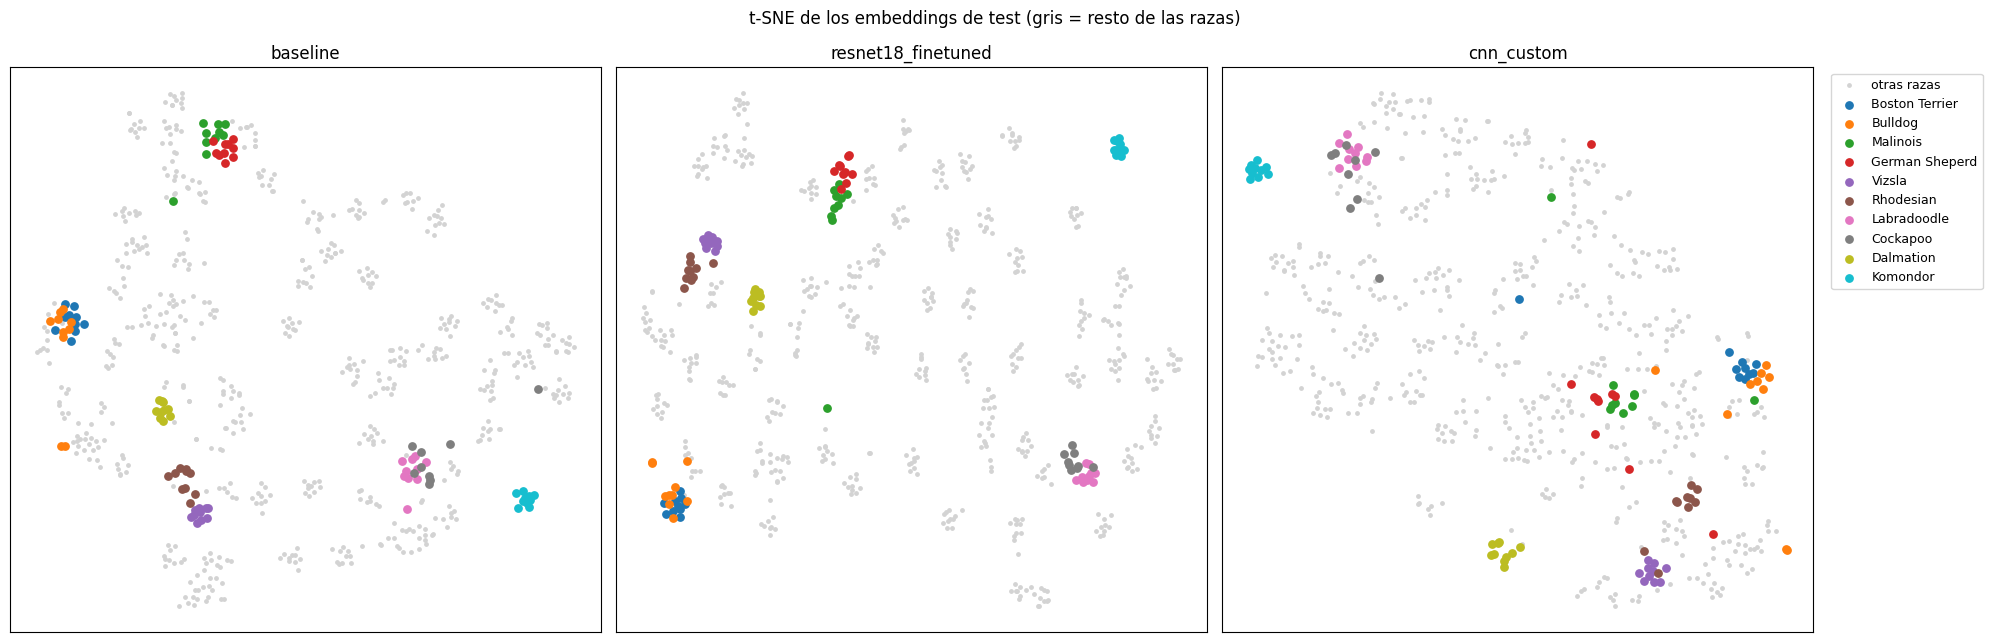

In [22]:
from sklearn.manifold import TSNE

# Subconjunto de razas: pares que se confunden + dos razas muy distintivas como referencia
RAZAS_VIS = ["Boston Terrier", "Bulldog", "Malinois", "German Sheperd", "Vizsla",
             "Rhodesian", "Labradoodle", "Cockapoo", "Dalmation", "Komondor"]

TEST = splits["split"].eq("test").to_numpy()
razas_test = splits.loc[TEST, "breed"].to_numpy()
colores = plt.cm.tab10(np.arange(len(RAZAS_VIS)))

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, (nombre, E) in zip(axes, EMB.items()):
    # t-SNE sobre todo test (696 imágenes); se colorean solo las razas del subconjunto
    Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(E[TEST])
    resto = ~np.isin(razas_test, RAZAS_VIS)
    ax.scatter(Z[resto, 0], Z[resto, 1], s=6, c="lightgray", label="otras razas")
    for raza, color in zip(RAZAS_VIS, colores):
        m = razas_test == raza
        ax.scatter(Z[m, 0], Z[m, 1], s=28, color=color, label=raza)
    ax.set_title(nombre)
    ax.set_xticks([])
    ax.set_yticks([])
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.suptitle("t-SNE de los embeddings de test (gris = resto de las razas)")
plt.tight_layout()
plt.show()

### Análisis: embeddings de los modelos entrenados

Repetí la evaluación de la Etapa 1 con la misma galería (`train`), las mismas consultas (`test` y el conjunto independiente) y la misma función de búsqueda, cambiando solo los embeddings: los del baseline (ResNet18 de ImageNet), los de la penúltima capa del Modelo A y los de la capa de embedding del Modelo B, todos de dimensión 512 y normalizados L2.

| Embeddings | NDCG@10 test | Precision@10 test | Accuracy test | NDCG@10 indep. | Accuracy indep. |
|---|---|---|---|---|---|
| Baseline (ImageNet) | 0,873 | 0,860 | 0,932 | 0,474 | 0,565 |
| ResNet18 fine-tuned (A) | **0,950** | **0,949** | **0,963** | **0,537** | **0,598** |
| CNN desde cero (B) | 0,753 | 0,739 | 0,822 | 0,275 | 0,315 |

**Modelo A.** El fine-tuning mejora claramente la búsqueda por similitud: en test, el NDCG@10 sube de 0,873 a 0,950 y la Precision@10 de 0,860 a 0,949 (en promedio, 9,5 de los 10 vecinos son de la raza correcta). Al entrenar la red para distinguir razas, la penúltima capa se reorganiza y agrupa las imágenes de cada raza, mientras que los embeddings de ImageNet son genéricos. La accuracy por voto de vecinos (0,963) es prácticamente igual a la del clasificador (0,966): la información necesaria para distinguir razas ya está en el embedding, y la última capa solo la combina linealmente.

**Modelo B.** Los embeddings de la CNN desde cero son peores que los del baseline sin entrenar, tanto en test (0,753) como en el independiente (0,275). Es coherente con su menor accuracy de clasificación y con su mayor sensibilidad al cambio de dominio.

**Conjunto independiente.** La mejora del Modelo A es menor (NDCG@10 de 0,474 a 0,537): el cambio de dominio analizado en la sección 8 sigue siendo el factor dominante.

**Visualización t-SNE.** La calculé sobre todas las imágenes de test y coloreé 10 razas: cuatro pares que se confunden (Boston Terrier/Bulldog, Malinois/German Sheperd, Vizsla/Rhodesian y Labradoodle/Cockapoo) y dos razas distintivas como referencia (Dalmation y Komondor). Elegí t-SNE en lugar de PCA porque conserva las vecindades locales, que son las que usa la búsqueda; en t-SNE las distancias entre grupos y el tamaño de los grupos no tienen un significado directo.

- **Baseline:** las razas forman nubes amplias y los pares parecidos aparecen mezclados.
- **ResNet18 fine-tuned:** las razas forman grupos compactos y bien separados. Vizsla y Rhodesian pasan a ser dos grupos distintos, y Labradoodle y Cockapoo se separan parcialmente. Boston Terrier y Bulldog siguen mezclados, lo que coincide con el error principal del clasificador y con la hipótesis de ruido en las etiquetas de esas razas.
- **CNN desde cero:** los grupos son más difusos y hay razas dispersas (Malinois, German Sheperd, Bulldog). Solo Dalmation y Komondor, que se distinguen por el color y la textura del pelaje, forman grupos compactos, lo que indica que la red aprendió sobre todo características de color y textura.

**Consecuencia para la aplicación.** Los embeddings del Modelo A son la mejor opción para la búsqueda por similitud. Si la aplicación los usa, hay que recalibrar `SIMILARITY_THRESHOLD`, porque el valor actual (0,836) se calibró con la distribución de similitudes del baseline.

## 10. Análisis de errores

TO-DO: ejemplos de falsos positivos y falsos negativos con la imagen y su score, razas con peor
desempeño e hipótesis sobre las causas.


Razas con peor F1 en test (Modelo A), comparadas con el Modelo B:


Modelo A                             Modelo B              \
                       FN   FP recall precision    f1       FN   FP recall   
Boston Terrier        4.0  2.0   0.60      0.75  0.67      1.0  1.0   0.90   
Bulldog               2.0  4.0   0.80      0.67  0.73      2.0  1.0   0.80   
American Spaniel      2.0  1.0   0.80      0.89  0.84      2.0  2.0   0.80   
Malinois              2.0  1.0   0.80      0.89  0.84      2.0  2.0   0.80   
German Sheperd        1.0  2.0   0.90      0.82  0.86      2.0  5.0   0.80   
Irish Spaniel         1.0  2.0   0.90      0.82  0.86      0.0  2.0   1.00   
Cockapoo              1.0  1.0   0.89      0.89  0.89      3.0  5.0   0.67   
Labradoodle           1.0  1.0   0.90      0.90  0.90      3.0  3.0   0.70   

                                  
                 precision    f1  
Boston Terrier        0.90  0.90  
Bulldog               0.89  0.84  
American Spaniel      0.80  0.80  
Malinois              0.80  0.80  
German Sheperd        0.62  0.70  
Irish Spaniel         0.83  0.91  
Cockapoo              0.55  0.60  
Labradoodle           0.70  0.70

Razas con peor F1 en test (Modelo B):


,FN,FP,recall,precision,f1
Cocker,6.0,6.0,0.40,0.40,0.40
Chihuahua,6.0,1.0,0.40,0.80,0.53
Cockapoo,3.0,5.0,0.67,0.55,0.60
Labrador,4.0,4.0,0.60,0.60,0.60
Lhasa,4.0,3.0,0.60,0.67,0.63
Yorkie,4.0,2.0,0.60,0.75,0.67
Schnauzer,2.0,6.0,0.80,0.57,0.67
Dingo,3.0,4.0,0.70,0.64,0.67


Score medio del Modelo A en test:


,count,mean,25%,50%,75%
acierto,,,,,
False,24.0,0.56,0.40,0.58,0.69
True,672.0,0.83,0.76,0.88,0.94


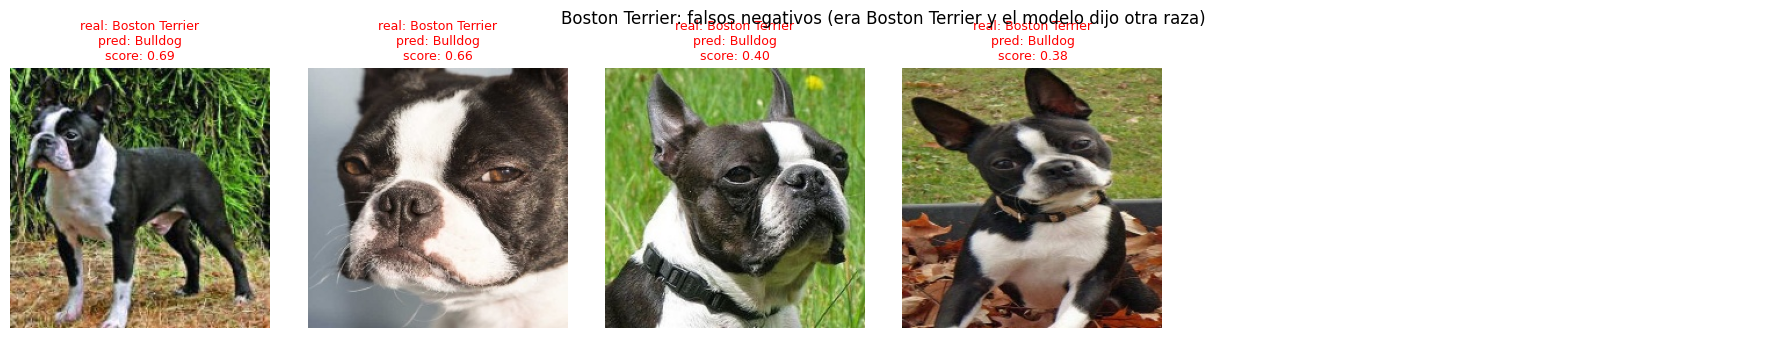

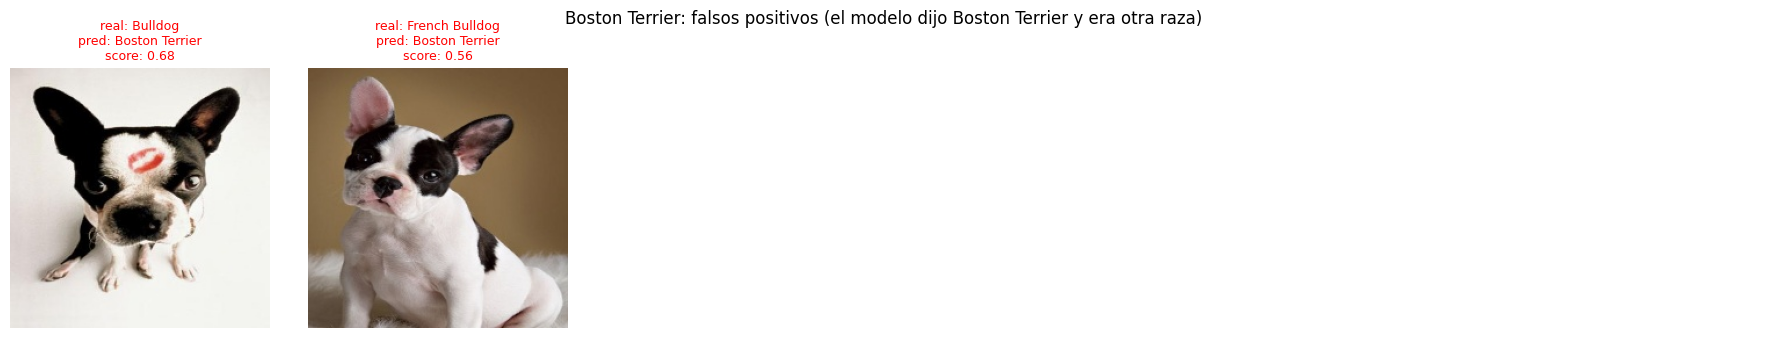

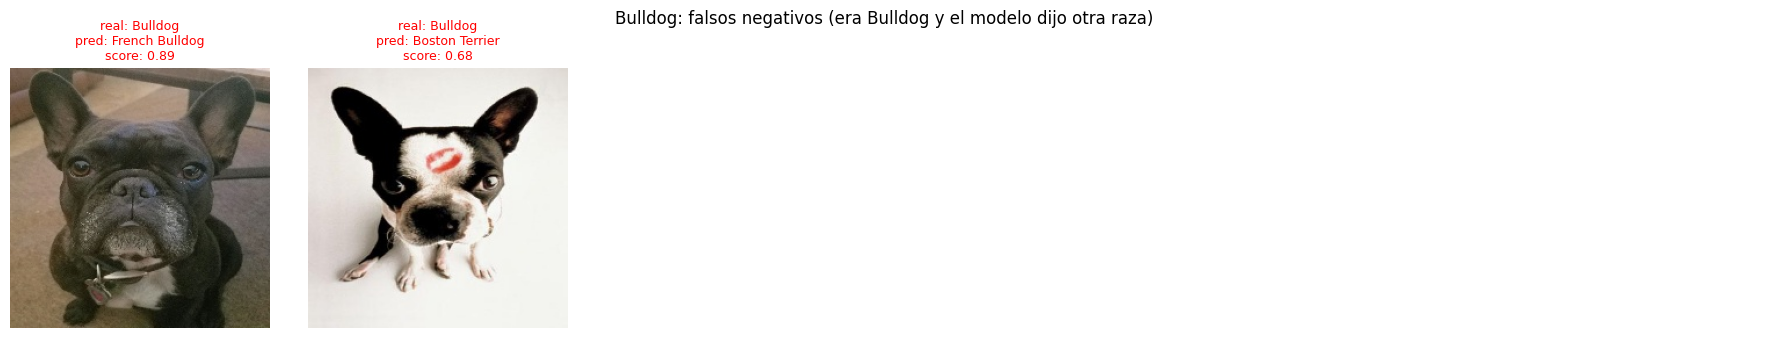

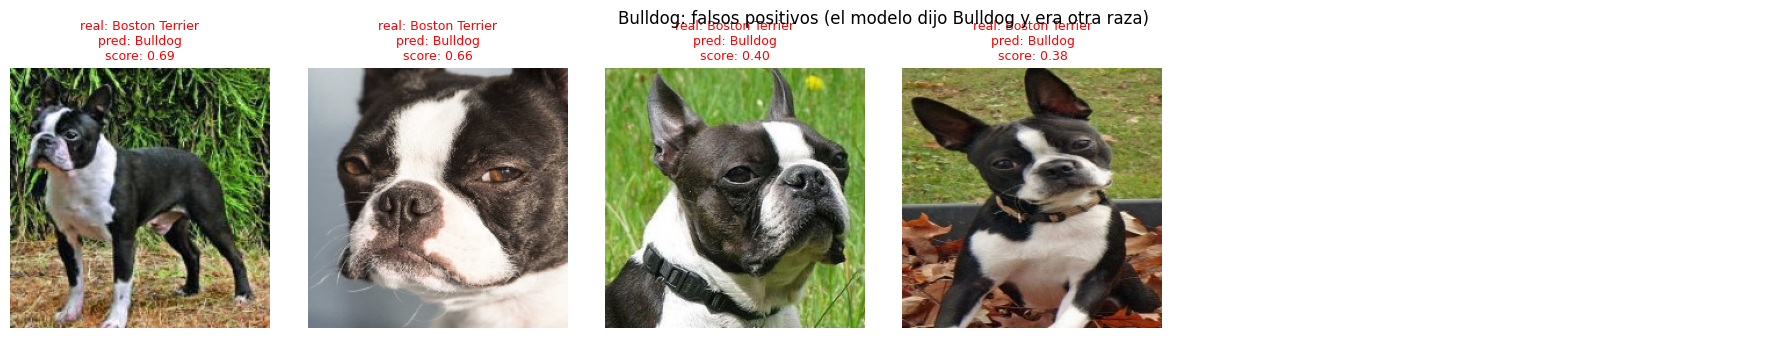

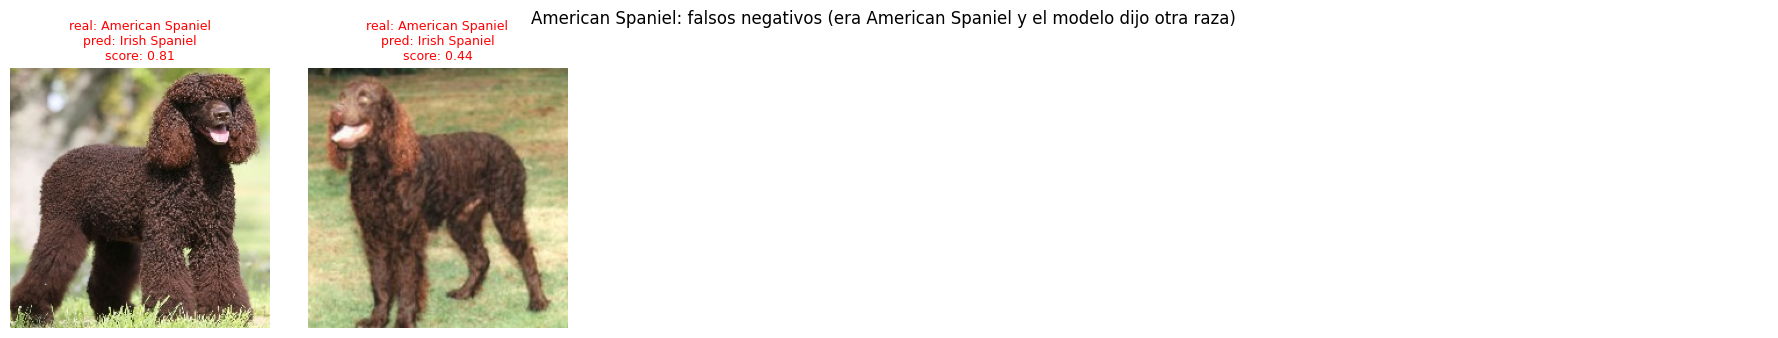

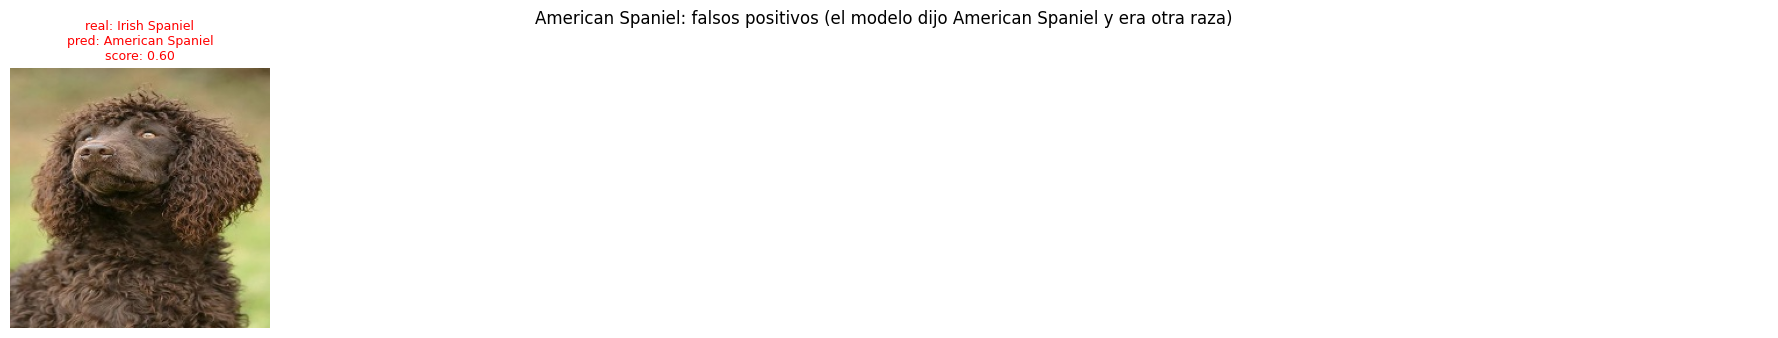

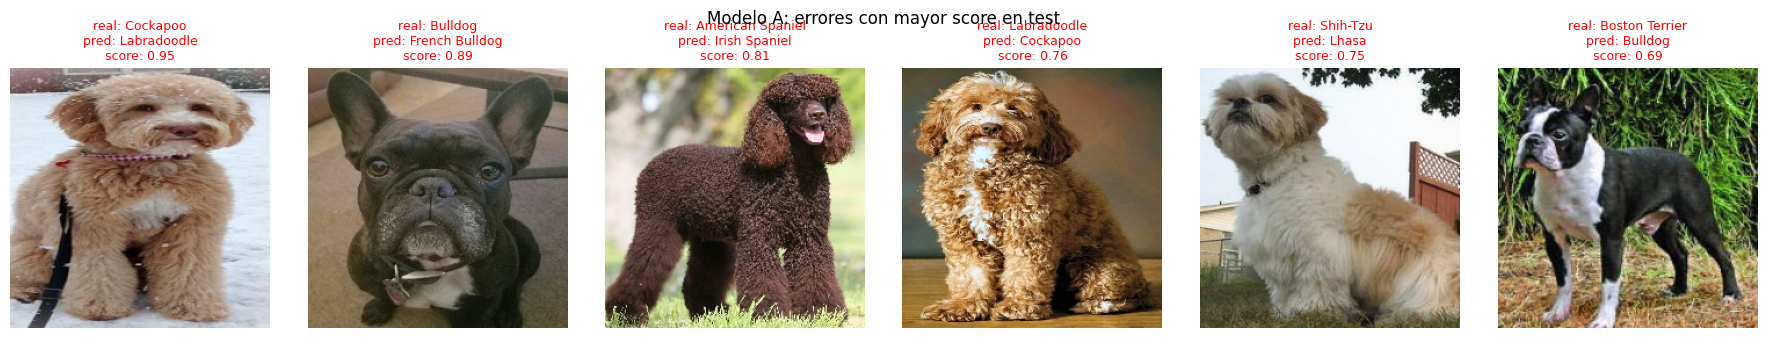

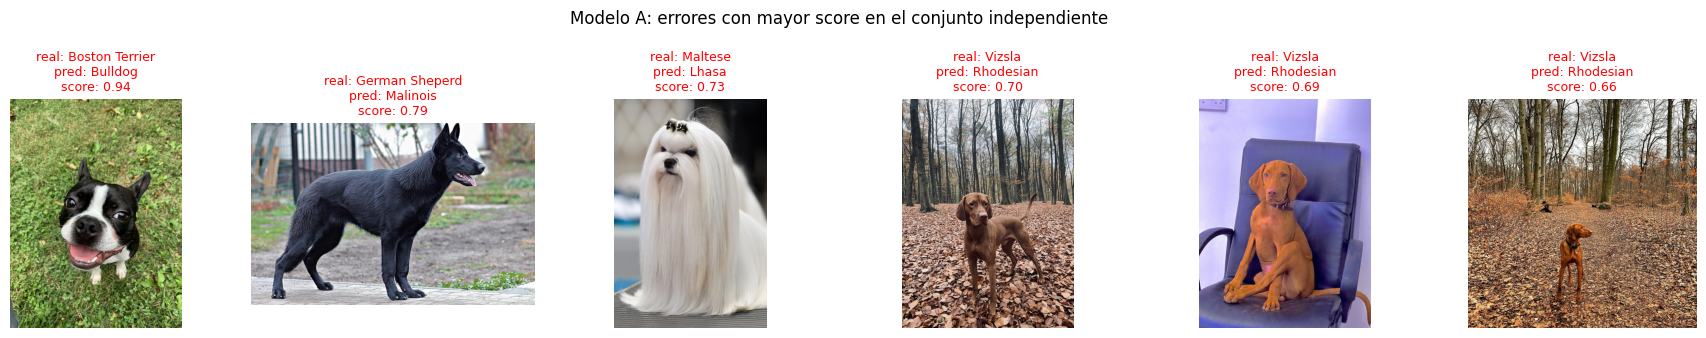

In [23]:
pa = preds[("resnet18_finetuned", "test")]
pb = preds[("cnn_custom", "test")]


def metricas_por_raza(p):
    filas = {}
    for raza in sorted(p["breed"].unique()):
        tp = int(((p["pred"] == raza) & (p["breed"] == raza)).sum())
        fp = int(((p["pred"] == raza) & (p["breed"] != raza)).sum())
        fn = int(((p["pred"] != raza) & (p["breed"] == raza)).sum())
        prec, rec, f1 = precision_recall_f1(tp, fp, fn)
        filas[raza] = {"FN": fn, "FP": fp, "recall": rec, "precision": prec, "f1": f1}
    return pd.DataFrame(filas).T


ma = metricas_por_raza(pa)
mb = metricas_por_raza(pb)
print("Razas con peor F1 en test (Modelo A), comparadas con el Modelo B:")
display(pd.concat({"Modelo A": ma, "Modelo B": mb}, axis=1).sort_values(("Modelo A", "f1")).head(8).round(2))
print("Razas con peor F1 en test (Modelo B):")
display(mb.sort_values("f1").head(8).round(2))

# Score (probabilidad del softmax) de los aciertos contra los errores
print("Score medio del Modelo A en test:")
display(pa.groupby("acierto")["prob"].describe()[["count", "mean", "25%", "50%", "75%"]].round(2))


def mostrar(filas, titulo, n=6):
    filas = filas.head(n)
    if filas.empty:
        print(f"{titulo}: sin casos")
        return
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.4))
    for ax in axes:
        ax.axis("off")
    for ax, (_, f) in zip(axes, filas.iterrows()):
        ax.imshow(cv2.imread(str(f["abs"]))[:, :, ::-1])
        ax.set_title(f"real: {f['breed']}\npred: {f['pred']}\nscore: {f['prob']:.2f}", fontsize=9, color="red")
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


# Falsos negativos y falsos positivos de las 3 razas con peor F1 del Modelo A
for raza in ma.sort_values("f1").index[:3]:
    fn = pa[(pa["breed"] == raza) & ~pa["acierto"]].sort_values("prob", ascending=False)
    fp = pa[(pa["pred"] == raza) & ~pa["acierto"]].sort_values("prob", ascending=False)
    mostrar(fn, f"{raza}: falsos negativos (era {raza} y el modelo dijo otra raza)")
    mostrar(fp, f"{raza}: falsos positivos (el modelo dijo {raza} y era otra raza)")

# Los errores más confiados del Modelo A: en test y en el conjunto independiente
errores_a = pa[~pa["acierto"]].sort_values("prob", ascending=False)
mostrar(errores_a, "Modelo A: errores con mayor score en test")
pi = preds[("resnet18_finetuned", "independent")]
mostrar(pi[~pi["acierto"]].sort_values("prob", ascending=False), "Modelo A: errores con mayor score en el conjunto independiente")

### Análisis de errores

**Cómo leer falsos positivos y falsos negativos con 70 clases.** Cada error cuenta dos veces: si un Boston Terrier se clasifica como Bulldog, es un falso negativo de Boston Terrier y un falso positivo de Bulldog. Por eso, para las razas con peor F1, muestro los dos casos. El score es la probabilidad que el softmax asigna a la raza predicha.

**Razas con peor desempeño (test).**

| Modelo A (ResNet18 fine-tuned) | F1 | Modelo B (CNN desde cero) | F1 |
|---|---|---|---|
| Boston Terrier | 0,67 | Cocker | 0,40 |
| Bulldog | 0,73 | Chihuahua | 0,53 |
| American Spaniel | 0,84 | Cockapoo | 0,60 |
| Malinois | 0,84 | Labrador | 0,60 |
| German Sheperd | 0,86 | Lhasa | 0,63 |
| Irish Spaniel | 0,86 | Yorkie | 0,67 |

Cada raza tiene unas 10 imágenes en test, así que cada error mueve la recall 10 puntos. Por eso no comparo razas aisladas entre modelos (por ejemplo, el Modelo B acierta más en Boston Terrier, pero son 3 imágenes) y me quedo con los patrones que se repiten.

**Hipótesis 1: razas parecidas.** Los errores del Modelo A se concentran en pares de razas visualmente muy similares, los mismos que identifiqué en el EDA y en la Etapa 1: Boston Terrier ↔ Bulldog, American Spaniel ↔ Irish Spaniel, Malinois ↔ German Sheperd y Cockapoo ↔ Labradoodle. Se distinguen por detalles finos (tamaño, proporciones del cuerpo, tono del pelaje) que una foto de 224×224 no siempre muestra, sobre todo en primeros planos.

**Hipótesis 2: ruido en las etiquetas de Bulldog.** Los cuatro falsos negativos de Boston Terrier son claramente Boston Terriers (pelaje blanco y negro, orejas erguidas, hocico corto), y el modelo los clasifica como Bulldog con scores de 0,38 a 0,69. Entre los falsos positivos de Boston Terrier aparece una imagen etiquetada como Bulldog con orejas erguidas y pelaje blanco y negro, rasgos de Boston Terrier o de Bulldog Francés y no de Bulldog inglés. En el EDA ya había encontrado un caso similar. Si la clase Bulldog del dataset incluye perros de este tipo, el modelo aprende que "blanco y negro con orejas erguidas" también puede ser Bulldog, y las dos clases se mezclan, como se vio en el t-SNE de la sección 9.

**Hipótesis 3: el Modelo B depende del color y la textura.** Las peores razas del Modelo B no son pares de razas parecidas en forma, sino razas chicas de pelo largo (Cocker, Lhasa, Yorkie, Cockapoo, Schnauzer) y razas de pelaje color arena (Labrador, Dingo). Coincide con lo observado en el t-SNE: la CNN entrenada desde cero aprendió sobre todo color y textura del pelaje, y no la forma de la cabeza o el cuerpo.

**Score de los errores.** En test, los aciertos del Modelo A tienen un score mediano de 0,88, mientras que los errores mostrados tienen scores entre 0,38 y 0,69: cuando el modelo se equivoca, suele hacerlo con menos confianza. En la aplicación, un score bajo puede usarse como señal para mostrar también la segunda raza más probable o para advertir que la predicción es dudosa.


## 11. Costo computacional

TO-DO: cantidad de parámetros, tamaño en MB, tiempo de inferencia por imagen en CPU y dimensión
del embedding de cada modelo.


In [26]:
import copy
import io
import time

from lib import preprocessing as prep

img = cv2.imread(str(splits.loc[splits["split"].eq("test"), "abs"].iloc[0]))
x = prep.to_tensor(prep.to_rgb_resized(img, classifier.image_size)).unsqueeze(0)

similarity.extract_embedding(img)  # inicializa el modelo del baseline (el mismo que usa la app)
modelos = {
    "baseline (ResNet18 ImageNet)": (similarity._model, EMB["baseline"].shape[1]),
    "Modelo A (ResNet18 fine-tuned)": (classifier.load_model("resnet18_finetuned"), EMB["resnet18_finetuned"].shape[1]),
    "Modelo B (CNN desde cero)": (classifier.load_model("cnn_custom"), EMB["cnn_custom"].shape[1]),
}

# Copias en CPU para medir sin mover los modelos que ya están cargados en la GPU
copias_cpu = {nombre: copy.deepcopy(model).cpu().eval() for nombre, (model, _) in modelos.items()}


def tamano_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / 1e6


# Tiempo en CPU: calentamiento largo y rondas intercaladas, rotando el orden de los modelos
RONDAS, REPETICIONES = 5, 20
tiempos = {nombre: [] for nombre in copias_cpu}
nombres = list(copias_cpu)
with torch.no_grad():
    for m in copias_cpu.values():
        for _ in range(20):  # calentamiento
            m(x)
    for ronda in range(RONDAS):
        orden = nombres[ronda % len(nombres):] + nombres[:ronda % len(nombres)]
        for nombre in orden:
            for _ in range(REPETICIONES):
                t0 = time.perf_counter()
                copias_cpu[nombre](x)
                tiempos[nombre].append(time.perf_counter() - t0)

filas = {}
for nombre, (model, dim) in modelos.items():
    filas[nombre] = {
        "parámetros (M)": sum(p.numel() for p in model.parameters()) / 1e6,
        "tamaño (MB)": tamano_mb(model),
        "tiempo CPU por imagen (ms)": 1000 * float(np.median(tiempos[nombre])),
        "dimensión del embedding": dim,
    }

print("Hilos de CPU usados por PyTorch:", torch.get_num_threads())
tabla_costo = pd.DataFrame(filas).T.round(2)
tabla_costo["dimensión del embedding"] = tabla_costo["dimensión del embedding"].astype(int)
tabla_costo

Hilos de CPU usados por PyTorch: 1


,parámetros (M),tamaño (MB),tiempo CPU por imagen (ms),dimensión del embedding
baseline (ResNet18 ImageNet),11.18,44.78,69.17,512
Modelo A (ResNet18 fine-tuned),11.21,44.93,57.98,512
Modelo B (CNN desde cero),2.52,10.13,81.51,512


### Análisis del costo computacional

| Modelo | Parámetros | Tamaño | Tiempo CPU por imagen | Embedding | Accuracy test |
|---|---|---|---|---|---|
| Baseline (ResNet18 ImageNet) | 11,18 M | 44,8 MB | ~69 ms | 512 | 0,932 (por vecinos) |
| Modelo A (ResNet18 fine-tuned) | 11,21 M | 44,9 MB | ~58 ms | 512 | 0,966 |
| Modelo B (CNN desde cero) | 2,52 M | 10,1 MB | ~82 ms | 512 | 0,818 |

**Cómo medí.** El tamaño es lo que ocupan los pesos guardados (float32, 4 bytes por parámetro). El tiempo es la mediana de una pasada hacia adelante con una imagen (batch de 1) en la CPU de Colab, con un solo hilo, después de un calentamiento. Medí los tres modelos intercalados en varias rondas, rotando el orden, porque en una primera medición el modelo que se medía primero salía mucho más lento por el calentamiento de la CPU. Los valores absolutos dependen de la máquina; lo comparable es la proporción entre modelos.

**Baseline contra Modelo A.** Tienen la misma arquitectura, y el Modelo A solo cambia la capa final (70 salidas en lugar de una capa identidad), por eso tienen prácticamente los mismos parámetros y el mismo tamaño. Hacen las mismas operaciones, así que su costo de inferencia es el mismo: la diferencia medida (~58 contra ~69 ms) es variabilidad de la máquina virtual. El fine-tuning mejora el rendimiento sin agregar costo.

**Modelo B: menos parámetros no significa más rápido.** La CNN propia tiene 4,4 veces menos parámetros y ocupa 4,4 veces menos espacio, pero es más lenta en CPU. El tiempo depende de la cantidad de operaciones, no de la cantidad de parámetros. La ResNet18 reduce la imagen apenas entra (convolución con stride 2 y max pool: de 224×224 a 56×56), mientras que la CNN propia aplica sus dos primeras convoluciones sobre la imagen completa de 224×224. Calculado a mano, la CNN propia hace unos 2.800 millones de multiplicaciones por imagen, contra unos 1.800 millones de la ResNet18: 1,5 veces más cálculo, en línea con la diferencia de tiempos. Achicar la imagen en la primera capa (stride 2) la haría más rápida.

**Dimensión del embedding.** Los tres modelos generan embeddings de 512 dimensiones: en la CNN propia elegí ese tamaño para la capa de embedding a propósito. Así, la base de vectores de la aplicación (que tiene una dimensión fija) y el costo de la búsqueda por similitud son los mismos con cualquiera de los tres modelos, y se pueden intercambiar sin cambiar nada más.

**Conclusión.** El Modelo A es el mejor compromiso: es el más preciso (0,966 en test, y el más robusto en el conjunto independiente), y su costo es igual al del baseline que la aplicación ya usaba. El Modelo B solo tiene ventaja en tamaño (10 MB), algo relevante para dispositivos con poca memoria, pero pierde casi 15 puntos de accuracy y no es más rápido. Con unos 60 ms por imagen en un solo hilo de CPU, los dos modelos son aptos para una aplicación interactiva sin GPU.

## 12. Comparación y elección final

TO-DO:

- Tabla comparativa de todas las métricas (Modelo A, Modelo B y baseline en la Etapa 1).
- Qué modelo usa la app para clasificar (Etapas 2 y 3) y qué embeddings para la búsqueda
  (`EMBEDDING_MODEL`), con su justificación.
- Búsqueda por similitud vs. clasificación supervisada: ventajas, limitaciones y cuándo conviene cada una.
- Trade-offs entre precisión, velocidad de inferencia, memoria y complejidad.


In [27]:
# Tabla comparativa: búsqueda por similitud (Etapa 1) con cada embedding y clasificadores (Etapa 2)
costo = tabla_costo.rename(index={
    "baseline (ResNet18 ImageNet)": "baseline",
    "Modelo A (ResNet18 fine-tuned)": "resnet18_finetuned",
    "Modelo B (CNN desde cero)": "cnn_custom",
})


def fila(m_test, m_ind, ndcg_test, ndcg_ind, nombre):
    return {
        "accuracy test": m_test["accuracy"],
        "precision test": m_test["precision"],
        "recall test": m_test["recall"],
        "specificity test": m_test["specificity"],
        "f1 test": m_test["f1"],
        "NDCG@10 test": ndcg_test,
        "accuracy indep.": m_ind["accuracy"],
        "recall indep.": m_ind["recall"],
        "NDCG@10 indep.": ndcg_ind,
        "parámetros (M)": costo.loc[nombre, "parámetros (M)"],
        "tamaño (MB)": costo.loc[nombre, "tamaño (MB)"],
        "CPU (ms/imagen)": costo.loc[nombre, "tiempo CPU por imagen (ms)"],
    }


filas = {}
for nombre, etiqueta in [("baseline", "Búsqueda - embeddings baseline"),
                         ("resnet18_finetuned", "Búsqueda - embeddings Modelo A"),
                         ("cnn_custom", "Búsqueda - embeddings Modelo B")]:
    r_t = res_emb[(nombre, "test")].rename(columns={"raza": "breed"})
    r_i = res_emb[(nombre, "independent")].rename(columns={"raza": "breed"})
    filas[etiqueta] = fila(metricas_macro(r_t), metricas_macro(r_i), r_t["ndcg"].mean(), r_i["ndcg"].mean(), nombre)

for nombre, etiqueta in [("resnet18_finetuned", "Clasificador - Modelo A"),
                         ("cnn_custom", "Clasificador - Modelo B")]:
    filas[etiqueta] = fila(metricas_macro(preds[(nombre, "test")]), metricas_macro(preds[(nombre, "independent")]),
                           np.nan, np.nan, nombre)

tabla_final = pd.DataFrame(filas).T.astype(float).round(3)
tabla_final.to_csv(settings.output_path / "tabla_final.csv")
if IN_COLAB:
    shutil.copy(settings.output_path / "tabla_final.csv", Path("/content/drive/MyDrive/tp2/output") / "tabla_final.csv")
tabla_final

,accuracy test,precision test,recall test,specificity test,f1 test,NDCG@10 test,accuracy indep.,recall indep.,NDCG@10 indep.,parámetros (M),tamaño (MB),CPU (ms/imagen)
Búsqueda - embeddings baseline,0.932,0.937,0.933,0.999,0.931,0.873,0.565,0.586,0.474,11.18,44.78,69.17
Búsqueda - embeddings Modelo A,0.963,0.966,0.963,0.999,0.962,0.950,0.598,0.624,0.537,11.21,44.93,57.98
Búsqueda - embeddings Modelo B,0.822,0.839,0.821,0.997,0.818,0.753,0.315,0.336,0.275,2.52,10.13,81.51
Clasificador - Modelo A,0.966,0.967,0.966,1.000,0.965,NaN,0.592,0.616,NaN,11.21,44.93,57.98
Clasificador - Modelo B,0.818,0.835,0.817,0.997,0.816,NaN,0.321,0.339,NaN,2.52,10.13,81.51


Umbral para embeddings del Modelo A (p2 de valid): 0.822   (baseline: 0.836)
Perros de valid rechazados como 'unknown': 2.0%
Imágenes sin perros rechazadas como 'unknown': 81.0% (21 imágenes)


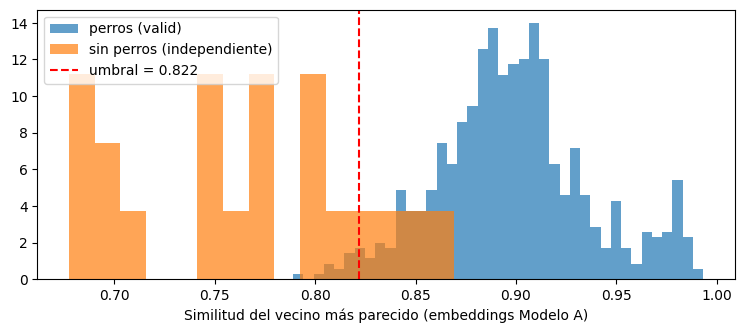

In [28]:
# Recalibración de SIMILARITY_THRESHOLD para los embeddings del Modelo A, con la misma regla de la sección 5:
# percentil 2 del score del vecino más parecido en valid (se acepta rechazar al 2 % de los perros reales)
E_a = EMB["resnet18_finetuned"]
r_valid_a = evaluar_busqueda(E_a, "valid", "cosine")
UMBRAL_A = float(np.quantile(r_valid_a["mejor_score"], 0.02))

# Solo para reportar: imágenes sin perros del conjunto independiente
IND = settings.dataset_path / "independent"
fuentes = pd.read_csv(IND / "fuentes.csv")
sin_perros = fuentes[fuentes["tipo"] == "sin_perro"]
classifier.set_active_model("resnet18_finetuned")
E_sin_a = np.array([classifier.extract_custom_embedding(cv2.imread(str(IND / a))) for a in sin_perros["archivo"]],
                   dtype=np.float32)
mejor_sin_a = (E_sin_a @ E_a[TRAIN].T).max(axis=1)

print(f"Umbral para embeddings del Modelo A (p2 de valid): {UMBRAL_A:.3f}   (baseline: 0.836)")
print(f"Perros de valid rechazados como 'unknown': {(r_valid_a['mejor_score'] < UMBRAL_A).mean():.1%}")
print(f"Imágenes sin perros rechazadas como 'unknown': {(mejor_sin_a < UMBRAL_A).mean():.1%} ({len(mejor_sin_a)} imágenes)")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(r_valid_a["mejor_score"], bins=40, alpha=0.7, label="perros (valid)", density=True)
ax.hist(mejor_sin_a, bins=15, alpha=0.7, label="sin perros (independiente)", density=True)
ax.axvline(UMBRAL_A, color="red", ls="--", label=f"umbral = {UMBRAL_A:.3f}")
ax.set_xlabel("Similitud del vecino más parecido (embeddings Modelo A)")
ax.legend()
plt.show()

### Comparación y elección final

**Resumen de la tabla.**

- Con los embeddings del Modelo A, la búsqueda por similitud y el clasificador dan prácticamente el mismo resultado: 0,963 contra 0,966 en test, y 0,598 contra 0,592 en el conjunto independiente (diferencias de 1 o 2 imágenes). Con los mismos embeddings, los dos enfoques llegan a la misma accuracy: lo que determina el rendimiento es la calidad de la representación, no el método de decisión.
- El Modelo A es el mejor en todas las métricas de rendimiento, en test y en el conjunto independiente, con el mismo costo de inferencia que el baseline.
- El Modelo B solo tiene ventaja en memoria (10 MB) y queda último en todas las métricas.
- La specificity (0,997 a 1,000) no sirve para comparar modelos con 70 clases, por la gran cantidad de verdaderos negativos de cada raza.

**Modelo para clasificar (Etapas 2 y 3): Modelo A (`resnet18_finetuned`).** Es el más preciso (accuracy 0,966 y F1 macro 0,965 en test) y el más robusto ante el cambio de dominio (0,592 en el conjunto independiente, contra 0,321 del Modelo B), con un costo de inferencia razonable para CPU (~58 ms por imagen). Es el modelo activo por defecto del servicio de clasificación.

**Embeddings para la búsqueda: `EMBEDDING_MODEL=resnet18_finetuned`, con `SIMILARITY_THRESHOLD=0,822`.** Los embeddings del Modelo A mejoran claramente la búsqueda: el NDCG@10 en test pasa de 0,873 a 0,950 y la Precision@10 de 0,860 a 0,949, sin costo adicional (misma arquitectura y misma dimensión, 512). El umbral se recalibró con la misma regla fijada en la sección 5 (percentil 2 del score del vecino más parecido en valid), porque el valor anterior (0,836) correspondía a la distribución de similitudes del baseline.

El costo de esta elección es un rechazo algo peor de las imágenes sin perros: con el nuevo umbral se rechaza el 81 % (17 de 21), contra el 95 % (20 de 21) del baseline. El Modelo A se entrenó solo con imágenes de perros, por lo que acerca cualquier imagen a alguna raza. Lo considero aceptable porque el objetivo de la búsqueda es encontrar perros parecidos, donde la mejora es grande, y porque en la Etapa 3 la detección con YOLO ya descarta las imágenes sin perros antes de clasificar. Si el rechazo de imágenes sin perros fuera la prioridad, convendría mantener los embeddings del baseline. Cambiar `EMBEDDING_MODEL` requiere reindexar la galería con esos embeddings.

**Búsqueda por similitud contra clasificación supervisada.**

| | Búsqueda por similitud | Clasificación supervisada |
|---|---|---|
| Entrenamiento | No es obligatorio: con embeddings de ImageNet ya se logra 0,932 en test | Obligatorio |
| Agregar una raza nueva | Basta con indexar imágenes de esa raza, sin reentrenar | Hay que reentrenar el modelo |
| Explicabilidad | Muestra las imágenes parecidas que justifican la predicción | Solo devuelve la raza y su probabilidad |
| Imágenes de razas desconocidas o sin perros | El umbral de similitud permite responder `unknown` | Siempre predice una de las 70 razas (conjunto cerrado) |
| Errores de etiqueta | Las imágenes mal etiquetadas de la galería afectan directamente al voto | Se diluyen en el entrenamiento |
| Costo | Hay que guardar la galería (7.652 × 512 floats ≈ 16 MB) y el costo de buscar crece con la galería (salvo con índices aproximados, como los de pgvector) | Costo fijo, independiente del tamaño del dataset |
| Infraestructura | Requiere una base de vectores | Solo el archivo del modelo |

La búsqueda conviene cuando las clases cambian con frecuencia, cuando hay pocas imágenes por clase o cuando importa mostrar ejemplos parecidos, como en esta aplicación. La clasificación conviene cuando las clases son fijas, hay suficientes datos etiquetados y se necesita una respuesta rápida con un costo fijo, sin base de datos. En este trabajo, los dos enfoques alcanzan la misma accuracy con los mismos embeddings, así que la aplicación puede ofrecer los dos: la clasificación para la respuesta principal y la búsqueda para mostrar perros parecidos.

**Trade-offs entre precisión, velocidad, memoria y complejidad.**

- **Baseline:** complejidad mínima (sin entrenamiento), buena precisión (0,932), ~60 ms por imagen y 45 MB. Es el que mejor rechaza imágenes sin perros.
- **Modelo A:** la mejor precisión (0,966) y la mejor robustez, con la misma velocidad y memoria que el baseline. A cambio, suma complejidad: requiere entrenar con GPU y elegir una estrategia de fine-tuning e hiperparámetros.
- **Modelo B:** la menor memoria (10 MB, 4,4 veces menos), pero es más lento en CPU (~82 ms, porque hace más operaciones al trabajar con la imagen completa en las primeras capas), es el menos preciso (0,818) y el que más cae ante el cambio de dominio (0,321). Además es el más complejo de desarrollar: hay que diseñar la arquitectura, y entrenarlo desde cero llevó más de una hora en una GPU T4.
- **Búsqueda contra clasificación:** con los mismos embeddings tienen la misma precisión. La búsqueda agrega memoria (la galería) e infraestructura (la base de vectores), a cambio de flexibilidad para agregar razas y de explicabilidad.

En conclusión, el Modelo A ofrece el mejor equilibrio: la mayor precisión sin costo adicional de inferencia respecto del baseline. El Modelo B solo se justificaría en un dispositivo con muy poca memoria, aceptando una pérdida importante de precisión.

## 13. Descargar los checkpoints

Descargalos y colocalos en `models/` de tu entorno local para que la aplicación los use.
Recordá publicarlos en un link público de solo lectura y ponerlo en el README y en el PR.


In [29]:
!ls -lh models/

try:
    from google.colab import files

    files.download(str(settings.model_path / settings.resnet18_model_name))
    files.download(str(settings.model_path / settings.cnn_custom_model_name))
except ImportError:
    print("Fuera de Colab: los checkpoints quedan en models/")

total 72M
-rw------- 1 root root 9.7M Nov 25 19:16 cnn_custom_base.pth
-rw------- 1 root root 9.7M Nov 25 19:50 cnn_custom_class_weights.pth
-rw------- 1 root root 9.7M Nov 25 19:50 cnn_custom.pth
-rw------- 1 root root  43M Nov 25 18:31 resnet18_finetuned.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>